# Исследовательский и статистический анализ пользовательского спроса в сервисе «Яндекс Афиша»

- Автор: Мельниченко Д.А.
- Дата: 26.07.2026

**Описание проекта:** Продуктовый отдел сервиса «Яндекс Афиша» зафиксировал общее изменение в пользовательском спросе, причины которого на данный момент не установлены. Чтобы разобраться, сработал ли здесь фактор сезонности, изменились ли предпочтения аудитории или сам ее состав, необходимо провести комплексное исследование. В рамках проекта предстоит изучить активность мобильных и десктопных пользователей, определить наиболее успешные категории мероприятий, а также выявить регионы и партнеров, ставших лидерами по выручке и заказам.

### Цели и задачи проекта

**Цель проекта:** Провести комплексный анализ данных «Яндекс Афиши» для выявления сезонных и структурных трендов в поведении клиентов, а также проверить статистические гипотезы для оптимизации продуктовых показателей сервиса.

**Задачи проекта:**
* Выполнить предобработку данных: обработать пропуски, устранить неявные дубликаты и очистить датасет от аномалий.
* Оптимизировать использование памяти и привести типы данных к корректным форматам.
* Конвертировать выручку из казахстанских тенге в российские рубли по ежедневному курсу и рассчитать метрику стоимости одного билета.
* Изучить сезонную динамику спроса, изменение долей категорий мероприятий, типов устройств и возрастных рейтингов при переходе от лета к осени.
* Проанализировать подневную активность пользователей, средний чек и недельную цикличность продаж.
* Оценить структуру рынка и степень концентрации бизнеса в разрезе регионов и билетных операторов с выделением ключевых лидеров.
* Сформулировать и статистически проверить гипотезы о различиях в поведении мобильных и десктопных пользователей, определив статистический тест.
* Разработать практические бизнес-рекомендации для продуктовой команды на основе результатов исследования.

### Описание данных

Для работы предоставлены три датасета:
1. **final_tickets_orders_df.csv** — данные о заказах билетов:
   * `order_id` — уникальный идентификатор заказа.
   * `user_id` — уникальный идентификатор пользователя.
   * `created_dt_msk` / `created_ts_msk` — дата и время создания заказа (московское время).
   * `event_id` — идентификатор мероприятия.
   * `cinema_circuit` — сеть кинотеатров (если не применимо, то будет значение 'нет').
   * `age_limit` — возрастное ограничение мероприятия.
   * `currency_code` — валюта оплаты.
   * `device_type_canonical` — тип устройства (`mobile` или `desktop`).
   * `revenue` — выручка с заказа.
   * `service_name` — название билетного оператора.
   * `tickets_count` — количество купленных билетов.
   * `total` — общая сумма заказа.
   * `days_since_prev` — количество дней с предыдущей покупки пользователя.
    <br>
2. **final_tickets_events_df.csv** — информация о мероприятиях и географии:
   * `event_id` — уникальный идентификатор мероприятия.
   * `event_name` — название мероприятия (в закодированном виде).
   * `event_type_description` — описание типа мероприятия.
   * `event_type_main` — основной тип мероприятия (концерт, театр и т.д.).
   * `organizers` — организаторы мероприятия.
   * `region_name` / `city_name` — название региона и города.
   * `city_id` / `venue_id` — уникальный идентификатор города и площадки.
   * `venue_name` / `venue_address` — название и адрес площадки.
    <br>
3. **final_tickets_tenge_df.csv** — информация о курсе тенге к российскому рублю за 2024 год:
   * `nominal` — номинал (100 тенге).
   * `data` — дата.
   * `curs` — курс тенге к рублю.
   * `cdx` — обозначение валюты (kzt).

### Содержимое проекта

* <a href="#p1">1. Загрузка данных и знакомство с ними</a>
    * <a href="#p1_1">1.1. Загрузка данных и первичный осмотр</a>
    * <a href="#p1_2">1.2. Промежуточный вывод после ознакомления с данными</a>
    * <a href="#p1_3">1.3. Подготовка единого датафрейма</a>
        * <a href="#p1_3_1">1.3.1. Формирование стратегии и программы предобработки данных</a>
* <a href="#p2">2. Предобработка данных</a>
    * <a href="#p2_1">2.1. Анализ пропусков в объединённом датафрейме</a>
    * <a href="#p2_2">2.2. Изучение значений в ключевых столбцах</a>
        * <a href="#p2_2_1">2.2.1. Категориальные значения</a>
        * <a href="#p2_2_2">2.2.2. Количественные значения</a>
        * <a href="#p2_2_3">2.2.3. Расчёт границ для удаления выбросов</a>
    * <a href="#p2_3">2.3. Проверка данных на явные и неявные дубликаты</a>
    * <a href="#p2_4">2.4. Изменение типов данных для работы с хронологией</a>
    * <a href="#p2_5">2.5. Создание новых признаков</a>
        * <a href="#p2_5_1">2.5.1. Приведение выручки к единой валюте (российскому рублю)</a>
        * <a href="#p2_5_2">2.5.2. Расчёт выручки с продажи одного билета на мероприятие</a>
        * <a href="#p2_5_3">2.5.3. Выделение месяца оформления заказа</a>
        * <a href="#p2_5_4">2.5.4. Определение сезона совершения заказа</a>
    * <a href="#p2_6">2.6. Финальная фильтрация и очистка данных от аномалий</a>
        * <a href="#p2_6_1">2.6.1. Оптимизация памяти и финальное приведение типов</a>
        * <a href="#p2_6_2">2.6.2. Общий промежуточный вывод по этапу предобработки данных</a>
* <a href="#p3">3. Исследовательский анализ данных (EDA)</a>
    * <a href="#p3_1">3.1. Анализ распределения заказов по сегментам и их сезонных изменений</a>
        * <a href="#p3_1_1">3.1.1. Динамика количества заказов по месяцам</a>
        * <a href="#p3_1_2">3.1.2. Сравнение распределения заказов летом и осенью</a>
        * <a href="#p3_1_3">3.1.3. Изучение изменения выручки с продажи одного билета по типам мероприятий</a>
        * <a href="#p3_1_4">3.1.4. Общий вывод по распределению заказов по категориям и их сезонных изменений</a>
    * <a href="#p3_2">3.2. Осенняя активность пользователей</a>
        * <a href="#p3_2_1">3.2.1. Расчет ежедневных показателей и анализ динамики осенней активности</a>
            * <a href="#p3_2_1_1">3.2.1.1. Динамика общего количества заказов по дням</a>
            * <a href="#p3_2_1_2">3.2.1.2. Динамика ежедневного количества уникальных пользователей (DAU)</a>
            * <a href="#p3_2_1_3">3.2.1.3. Динамика среднего количества заказов на одного пользователя</a>
            * <a href="#p3_2_1_4">3.2.1.4. Динамика средней стоимости одного билета</a>
        * <a href="#p3_2_2">3.2.2. Анализ недельной цикличности активности пользователей</a>
        * <a href="#p3_2_3">3.2.3. Общий вывод по анализу осенней активности</a>
    * <a href="#p3_3">3.3. Популярные события и партнёры</a>
        * <a href="#p3_3_1">3.3.1. Анализ распределения мероприятий и заказов по регионам</a>
        * <a href="#p3_3_2">3.3.2. Анализ распределения заказов и выручки по билетным операторам</a>
        * <a href="#p3_3_3">3.3.3. Общий промежуточный вывод по распределению данных между категориями</a>
* <a href="#p4">4. Статистический анализ данных (Проверка гипотез)</a>
    * <a href="#p4_1">4.1. Сравнение количества заказов на пользователя</a>
        * <a href="#p4_1_1">4.1.1. Исследование структуры данных, визуализация распределений и выбор критерия</a>
        * <a href="#p4_1_2">4.1.2. Формулирование гипотез, проведение теста и подведение итогов</a>
    * <a href="#p4_2">4.2. Сравнение времени между заказами пользователей</a>
        * <a href="#p4_2_1">4.2.1. Подготовка данных и исследование распределений времени между заказами</a>
        * <a href="#p4_2_2">4.2.2. Формулирование гипотез, проведение теста и подведение итогов</a>
    * <a href="#p4_3">4.3. Итоги статистического анализа и методологическое обоснование</a>
* <a href="#p5">5. Общий вывод и бизнес-рекомендации</a>

## <a id="p1"></a> Загрузка данных и знакомство с ними
<br>

**Для реализации проекта импортируем все необходимые библиотеки:**
* `pandas` — для загрузки, предобработки и анализа табличных данных.
* `matplotlib.pyplot` — для построения графиков и визуального анализа распределений.
* `seaborn` — для создания статистической графики.
* `scipy.stats` — для проведения статистических тестов и проверки гипотез.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon, mannwhitneyu

### <a id="p1_1"></a> Загрузка данных и первичный осмотр

*Загрузим первый датасет с информацией о заказах билетов (`orders_df`) и выведем первые строки, а также общую информацию о структуре таблицы для первичного ознакомления с данными:*

In [2]:
orders_df = pd.read_csv("https://code.s3.yandex.net/datasets/final_tickets_orders_df.csv")

display(orders_df.head())
print()
orders_df.info()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), object(7)


**На основе общей информации о первом датасете можно сделать следующие выводы:**
* **Объём данных**: таблица содержит 290 849 строк и 14 столбцов, которые полностью соответствуют описанию.
* **Анализ пропусков**: почти все поля полностью заполнены. Пропуски присутствуют только в столбце `days_since_prev` (содержит 268 909 заполненных строк). Данная особенность обоснована логикой бизнес-процесса (первые покупки пользователей) и является корректной.
* **Типы данных**: столбцы с датой и временем (`created_dt_msk` и `created_ts_msk`) имеют строковый тип `object` и требуют последующего преобразования в формат даты и времени (`datetime`), для проведения корректного исследовательского анализа.

<br>*Загрузим второй датасет (`events_df`), содержащий справочную информацию о проводимых мероприятиях, регионах и площадках, а также выведем его структуру для ознакомления:*

In [3]:
events_df = pd.read_csv("https://code.s3.yandex.net/datasets/final_tickets_events_df.csv")

display(events_df.head())
print()
events_df.info()

,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


**На основе общей информации о втором датасете можно сделать следующие выводы:**
* **Объём данных**: таблица содержит 22 427 строк и 11 столбцов, что так же соответствуют описанию.
* **Анализ пропусков**: во всех полях данные полностью заполнены и не содержат пропущенных значений.
* **Типы данных**: установленные типы данных соответствуют содержимому столбцов, корректировка на данном этапе не требуется.

<br>*Загрузим третий, последний датасет (`tenge_df`) с информацией о курсе казахстанского тенге, и выведем его структуру для ознакомления:*

In [4]:
tenge_df = pd.read_csv("https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv")

display(tenge_df.head())
print()
tenge_df.info()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


**На основе общей информации о третьем датасете делаем следующие выводы:**
* **Объём данных**: таблица содержит 357 строк и 4 столбца, соответствующие данным описания.
* **Анализ пропусков**: все поля полностью заполнены и не содержат пропущенных значений.
* **Типы данных**: столбец с датой `data` имеет строковый тип `object` и требует последующего преобразования в формат `datetime` для корректной стыковки с основным массивом.

### <a id="p1_2"> Промежуточный вывод после ознакомления с данными

*В ходе первичного осмотра трёх предоставленных датафреймов критических замечаний и глобальных нарушений в структуре не обнаружено. Данные во всех датасетах соответствуют описанию, а пропуски в таблице заказов логически обоснованы. Для проведения комплексного исследовательского анализа необходимо скорректировать типы данных и провести предобработку. Но перед этим объединим исходные первые две таблицы.*

### <a id="p1_3"> Подготовка единого датафрейма

**Перед объединением таблиц необходимо провести техническую валидацию** ключевого поля `event_id` в справочнике мероприятий (`events_df`). 
<br>Мы должны убедиться в абсолютной уникальности идентификаторов событий. Если в справочнике обнаружатся дубликаты ключей, последующая операция слияния методом `merge()` искусственно раздует итоговый датафрейм, создав ложные дубликаты заказов и исказив финансовые метрики платформы. Оценим размерность таблицы и проверим ключи на уникальность.

In [5]:
# Проверяем уникальность ключей event_id в справочнике мероприятий перед merge
print(f"Количество строк в таблице мероприятий: {events_df.shape[0]}")
print(f"Количество уникальных event_id: {events_df['event_id'].nunique()}")
print(f"Все ключи event_id уникальны: {events_df['event_id'].is_unique}")

Количество строк в таблице мероприятий: 22427
Количество уникальных event_id: 22427
Все ключи event_id уникальны: True


<br>Проверка подтвердила полную уникальность идентификаторов: количество строк в справочнике мероприятий совпадает с числом уникальных `event_id` (**22 427**), а метод `.is_unique` вернул значение `True`. Скрытые дубликаты отсутствуют, структура справочника чиста, что позволяет безопасно перейти к этапу формирования единого аналитического массива данных.

<br>Объединим таблицу заказов (`orders_df`) с проверенным справочником мероприятий (`events_df`) с помощью метода `merge()` по общему ключу `event_id`, применив тип связи `how='left'`, чтобы гарантированно сохранить абсолютно все записи о совершенных покупках пользователей.

In [6]:
tickets_df = orders_df.merge(events_df, on='event_id', how='left')

<br>**Проверка структуры объединённого датафрейма**
<br>*Выведем первые строки нового датафрейма `tickets_df` и ознакомимся с его общей информацией, чтобы убедиться в корректности слияния таблиц и оценить изменения в структуре данных:*

In [7]:
display(tickets_df.head())
print()
tickets_df.info()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,спектакль,театр,№3322,Каменевский регион,Глиногорск,213.0,3972.0,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6"
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,...,40efeb04-81b7-4135-b41f-708ff00cc64c,событие,выставки,№4850,Каменевский регион,Глиногорск,213.0,2941.0,"Музыкальная школа для детей ""Аккаунт"" Лтд","алл. Шмидта, д. 9 стр. 4"
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,цирковое шоу,другое,№1540,Каменевский регион,Глиногорск,213.0,4507.0,"Училище искусств ""Нирвана"" Инк","алл. Юбилейная, д. 5/6"
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,...,2f638715-8844-466c-b43f-378a627c419f,выставка,другое,№5049,Североярская область,Озёрск,2.0,3574.0,"Театр альтернативного искусства ""Ода"" Лимитед","алл. Есенина, д. 243 к. 3/8"
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,10d805d3-9809-4d8a-834e-225b7d03f95d,шоу,стендап,№832,Озернинский край,Родниковецк,240.0,1896.0,"Театр кукол ""Огни"" Инкорпорэйтед","ш. Набережное, д. 595 стр. 8"



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                290849 non-null  int64  
 1   user_id                 290849 non-null  object 
 2   created_dt_msk          290849 non-null  object 
 3   created_ts_msk          290849 non-null  object 
 4   event_id                290849 non-null  int64  
 5   cinema_circuit          290849 non-null  object 
 6   age_limit               290849 non-null  int64  
 7   currency_code           290849 non-null  object 
 8   device_type_canonical   290849 non-null  object 
 9   revenue                 290849 non-null  float64
 10  service_name            290849 non-null  object 
 11  tickets_count           290849 non-null  int64  
 12  total                   290849 non-null  float64
 13  days_since_prev         268909 non-null  float64
 14  event_name         

<br>**Выводы по результатам объединения данных**
<br>*Слияние основной таблицы заказов и справочника мероприятий прошло успешно. Анализ общей информации о полученном датафрейме `tickets_df` позволяет сделать следующие выводы:*
* **Размерность**: итоговый массив данных содержит 290 849 строк и 24 столбца. Количество строк полностью совпало с исходной таблицей заказов `orders_df`, что подтверждает корректность использования типа связи `how='left'`.
* **Появление новых пропусков**: во всех столбцах, добавленных из таблицы `events_df` (начиная с поля `event_name`), зафиксировано одинаковое количество заполненных строк — 290 611 из 290 849. Данные пропуски могли возникнуть из-за возможного отсутствия некоторых идентификаторов `event_id` в справочнике мероприятий. На этапе предобработки необходимо будет рассчитать количество этих пропусков, чтобы принять обоснованное решение об их обработке.
* **Изменение типов данных**: из-за появления пропусков при слиянии тип данных у столбцов с идентификаторами городов `city_id` и площадок `venue_id` автоматически изменился на вещественный `float64`. Данную особенность также предстоит учесть и исправить на этапе изменения типов данных, вернув им логичный целочисленный формат после работы с пропусками.

<br>

#### <a id="p1_3_1"> Формирование стратегии и программы предобработки данных

На основе первичного визуального и структурного анализа данных сформирована следующая программа по их подготовке к исследовательскому анализу (EDA):

* **Исследование и обработка пропущенных значений:** Проверить природу пропусков в данных и убедиться, что в столбце `days_since_prev` они обусловлены объективными причинами (первой покупкой), а не техническими сбоями.
* **Анализ уникальных значений в столбцах:** Проверить категориальные признаки на предмет скрытых пропусков, опечаток или разного регистра. Оценить диапазоны числовых переменных на наличие логических несоответствий.
* **Поиск дубликатов:** Провести комплексную проверку датасета на наличие как полных дубликатов строк, так и неявных повторов по ключевым логическим комбинациям.
* **Преобразование временных типов:** Привести столбцы с датами из исходного текстового формата (`object`) к специализированному типу данных даты и времени для корректного последующего анализа.
* **Конвертация валют и создание расчетных признаков:** Привести финансовые показатели к единой валюте (российскому рублю) с использованием справочника курсов, а также рассчитать дополнительные метрики для оценки сезонности, стоимости единичного билета и периодов совершения заказов.
* **Фильтрация экстремальных значений:** Выявить математические границы распределений и очистить итоговый массив от невалидных данных и аномальных выбросов.
* **Оптимизация использования ресурсов:** Сменить типы данных на более оптимальные с целью снижения объёма занимаемой оперативной памяти и ускорения последующих вычислений.

<div style="border:solid #D3D3D3 2px; border-radius: 10px; padding: 15px">
<h3> Комментарий ревьюера <a class="tocSkip"></h3>
<h4> Загрузка данных <a class="tocSkip"></h4>
<div style="border-radius: 10px" class="alert alert-success">
<b>Отлично ✅:</b> 
    
* С выгрузкой данных справились! 

    
* Хорошо, что убеждаешься в корректности данных! Если при подгрузке возникнут проблемы, а мы их не обнаружим, все последующие расчеты могут быть искажены.

    
* Круто, что не забываешь зафиксировать промежуточные наблюдения в выводах! Если потребуется вернуться к проекту спустя время, будет проще освежить в памяти все ключевые этапы работы, что и почему мы делали, что получили.

</div>

<div style="border-radius: 10px" class="alert alert-warning">
<b>Точки роста💡:</b> 

По результатам проверки корректности загруженных данных мы планируем дальнейшие шаги по обработке. Здесь можно было бы отметить, что нам потребуется привести выручку к единой валюте, убедиться, что пропуски имеются только у первых заказов, выполнить проверку на дубликаты (полные и неполные), проверить категориальные столбцы на предмет неявных дубликатов (разный регистр, разный формат записи, опечатки) и все числовые столбцы на наличие невалидных значений и аномалий, опционально сменить типы данных на более оптимальные, чтобы уменьшить объем занимаемой памяти.

</div>

<div style="background-color: grey; border: 2px solid blue; border-radius: 20px; padding: 15px 25px; display: inline-block; color: black;">
    💬 <b>Юля, спасибо за ценный совет!</b>💡
    <br>Я выделил логический мостик между осмотром и обработкой в отдельный подпункт <b>1.3.1. «Формирование стратегии и программы предобработки данных»</b>. Прописал там пошаговую программу в общих чертах — строго в той последовательности, в которой далее выполняются этапы в Шаге 2 (от анализа пропусков до финальной очистки и в конце я провёл оптимизацию по типам данных). Теперь структура выглядит логично!
    <br>Исправил критический момент с преждевременным слиянием таблиц (о котором ты говорила в комментарии после второго шага): прямо в раздел 1.3 перед методом <code>merge()</code> добавил блок технической валидации. Проверил уникальность <code>event_id</code> в справочнике мероприятий (метод вернул <code>True</code> при 22 427 строках), что полностью исключает риск ложного раздувания обещго датафрейма при склейке.
</div>

<div style="border:solid #D3D3D3 2px; border-radius: 10px; padding: 15px">
<h3> Комментарий ревьюера 2 ✅ <a class="tocSkip"></h3>
    
Отлично!

## <a id="p2"> Предобработка данных

### <a id="p2_1"> Анализ пропусков в объединённом датафрейме

Оценим количество и долю пропущенных значений в столбце `days_since_prev`, а также в полях, полученных из таблицы событий (на примере `event_name`), чтобы определить масштаб пропусков и принять решение об их обработке:

*Считаем абсолютное количество пропусков:*

In [8]:
missing_absolute = tickets_df[['days_since_prev', 'event_name']].isna().sum()

*Считаем долю пропусков в процентах от общего числа строк:*

In [9]:
missing_relative = (tickets_df[['days_since_prev', 'event_name']].isna().mean() * 100).round(2)

*Объединяем результаты в одну сводную таблицу и выводим её на экран:*

In [10]:
missing_summary = pd.DataFrame({
    'Абсолютные пропуски (шт.)': missing_absolute,
    'Доля пропусков (%)': missing_relative
})

display(missing_summary)

,Абсолютные пропуски (шт.),Доля пропусков (%)
days_since_prev,21940,7.54
event_name,238,0.08


<br>**Вывод по результатам анализа и обработки пропусков:**
<br>Поскольку пропуски в данных о мероприятиях (`event_name`) составляют всего 0.08%, их исключение полностью безопасно и не повлияет на качество анализа. Удалим эти строки.
<br>В то же время 7.54% пропусков в столбце количества дней (`days_since_prev`) являются естественными — они отражают информацию о самых первых покупках пользователей на платформе, когда предыдущая история заказов отсутствует. Проверим эту гипотезу математически, чтобы убедиться, что на каждого пользователя приходится не более одного пропуска.


<br>*Удаляем строки с заказами, у которых есть пропуски по событиям:*

In [11]:
tickets_df = tickets_df.dropna(subset=['event_name']).reset_index(drop=True)

*Проверяем гипотезу: присутствует ли у каждого пользователя с пропусками ровно один пропуск (первый заказ)*

In [12]:
users_with_na = tickets_df[tickets_df['days_since_prev'].isna()]['user_id']

print(f"Общее количество пропусков в столбце days_since_prev: {tickets_df['days_since_prev'].isna().sum()}")
print(f"Количество уникальных пользователей с пропусками: {users_with_na.nunique()}")
print(f"Максимальное количество пропусков на одного пользователя: {users_with_na.value_counts().max()}")


Общее количество пропусков в столбце days_since_prev: 21913
Количество уникальных пользователей с пропусками: 21913
Максимальное количество пропусков на одного пользователя: 1


*Проверяем остаток пропусков:*

In [13]:
print(tickets_df.isna().sum())

order_id                      0
user_id                       0
created_dt_msk                0
created_ts_msk                0
event_id                      0
cinema_circuit                0
age_limit                     0
currency_code                 0
device_type_canonical         0
revenue                       0
service_name                  0
tickets_count                 0
total                         0
days_since_prev           21913
event_name                    0
event_type_description        0
event_type_main               0
organizers                    0
region_name                   0
city_name                     0
city_id                       0
venue_id                      0
venue_name                    0
venue_address                 0
dtype: int64


<br>**Итог проверки пропущенных значений:**

Контрольная проверка методом `isna().sum()` показывает наличие **21 913** пропусков строго в столбце `days_since_prev`. 
<br>Математическая проверка подтвердила, что данные пустоты привязаны исключительно к первым покупкам клиентов на платформе. Поэтому **оставить эти пропуски как есть (NaN)** гарантирует максимальную точность расчётов и защиту результатов будущих статистических тестов от искажений.

<br>

### <a id="p2_2"></a> Изучение значений в ключевых столбцах

<br>**Оценка количества уникальных значений по всем признакам**
<br>Для выбора оптимальной стратегии проверки номинальных (категориальных) и количественных данных необходимо оценить масштабы разнообразия значений в каждом столбце датафрейма. Выведем количество уникальных элементов по всем полям. Это позволит выявить столбцы с высокой вариативностью, требующие особого внимания при поиске скрытых опечаток и аномалий.

<br>*Выведим количество уникальных значений для каждого столбца датафрейма:*

In [14]:
tickets_df.nunique()

order_id                  290611
user_id                    21933
created_dt_msk               153
created_ts_msk            280753
event_id                   22427
cinema_circuit                 6
age_limit                      5
currency_code                  2
device_type_canonical          2
revenue                    42522
service_name                  36
tickets_count                 22
total                      55458
days_since_prev              149
event_name                 15248
event_type_description        20
event_type_main                7
organizers                  4293
region_name                   81
city_name                    352
city_id                      353
venue_id                    3225
venue_name                  3217
venue_address               3225
dtype: int64

<br>

#### <a id="p2_2_1"></a> Категориальные значения:

Для проверки категориальных данных мы отбираем столбцы с `сетями кинотеатров`, `возрастными ограничениями`, `валютой оплаты`, `типом устройства`, `названием билетного оператора`, `типом мероприятия` и `названием региона`. 
<br>Именно по этим полям мы дальше будем изучать активность пользователей, продажи у разных партнёров и проверять гипотезы продуктового отдела. Поэтому сейчас важно убедиться, что в этих данных нет ошибок или скрытых опечаток.

По результатам общей оценки видно, что признак `region_name` содержит **81** уникальное значение, что делает его самым вариативным категориальным полем проекта. При проверке номинальных признаков с таким количеством элементов ошибки и скрытые дубликаты обычно концентрируются в самых редких записях. Исследуем хвостовые значения этого столбца, отсортировав их по возрастанию частоты, чтобы проверить качество и формат записи данных.

<br>*Исследуем уникальные значения в ключевых категориальных столбцах датафрейма (кроме `region_name`) с помощью цикла:*

In [15]:
categorical_cols = ['cinema_circuit', 'age_limit', 'currency_code', 'device_type_canonical', 'service_name', 'event_type_main']

for col in categorical_cols:
    print(f"Уникальные значения для столбца {col}:")
    print(tickets_df[col].unique())
    print("-" * 100)


Уникальные значения для столбца cinema_circuit:
['нет' 'Другое' 'Киномакс' 'КиноСити' 'Москино' 'ЦентрФильм']
----------------------------------------------------------------------------------------------------
Уникальные значения для столбца age_limit:
[16  0 18 12  6]
----------------------------------------------------------------------------------------------------
Уникальные значения для столбца currency_code:
['rub' 'kzt']
----------------------------------------------------------------------------------------------------
Уникальные значения для столбца device_type_canonical:
['mobile' 'desktop']
----------------------------------------------------------------------------------------------------
Уникальные значения для столбца service_name:
['Край билетов' 'Мой билет' 'За билетом!' 'Лови билет!'
 'Билеты без проблем' 'Облачко' 'Лучшие билеты' 'Прачечная' 'Быстробилет'
 'Дом культуры' 'Весь в билетах' 'Билеты в руки' 'Тебе билет!'
 'Show_ticket' 'Городской дом культуры' 'Яблоко' '

<br>*Выведем ТОП — 10 самых редких названий регионов для поиска опечаток и аномалий:*

In [16]:
print("Топ-10 самых редких регионов по количеству заказов:")
display(tickets_df['region_name'].value_counts(ascending=True).head(10))


Топ-10 самых редких регионов по количеству заказов:


region_name
Теплоозёрский округ          7
Сосноводолинская область    10
Верхозёрский край           11
Крутоводский регион         18
Лесноярский край            19
Яснопольский округ          21
Светолесский край           24
Островогорский округ        31
Кристальная область         35
Тихогорская область         48
Name: count, dtype: int64

<br>**Вывод по результатам анализа категориальных признаков**

Проведённый анализ уникальных значений ключевых категориальных полей подтверждает, что данные корректны:
* **Устройства и валюты:** в столбцах устройств `device_type_canonical` и валют `currency_code` присутствуют только нужные нам категории (`mobile`/`desktop` и `rub`/`kzt`), всё строго по условиям задачи.
* **Возрастные ограничения:** в столбце `age_limit` представлены стандартные категории, странные или аномальные числа отсутствуют.
* **Текстовые столбцы:** в полях типов мероприятий `event_type_main`, сетей кинотеатров `cinema_circuit` и билетных операторов `service_name` все данные логичные. В них не обнаружено скрытых повторов из-за опечаток, разного регистра или лишних пробелов, а значения `'нет'` и `'другое'` являются нормальными заглушками.
* **Названия регионов:** анализ ТОП — 10 самых редких значений подтвердил, что все наименования написаны в едином формате, с заглавной буквы и не содержат скрытых пропусков, опечаток или дублирования из-за разного регистра. Поле `region_name` полностью валидно.

Категориальные данные полностью готовы к дальнейшему исследованию.

<br>

#### <a id="p2_2_2"></a> Количественные значения:

В этом подразделе мы исследуем ключевые числовые показатели нашего датасета — **количество билетов** в одном заказе и **выручку**. С помощью горизонтального «ящика с усами» (Boxplot) и классической гистограммы распределения частот, а так же базовой статистики оценим, как распределены эти данные, а также поищем возможные ошибки, аномалии и крупные выбросы, которые в дальнейшем могут исказить результаты исследования.

Чтобы оптимизировать процесс визуализации и избежать дублирования кода, разработаем универсальную автоматизированную функцию `plot_hist_and_box()`. Данный инструмент на едином холсте с общей осью X будет объединять два взаимодополняющих графика:
1. **Горизонтальный ящик с усами (Boxplot)** — для наглядной фиксации математических границ распределения и детекции единичных выбросов.
2. **Классическую гистограмму (Histogram)** — для детальной оценки частоты и плотности ядра данных.

Сразу под графиками функция автоматически выведет сводную таблицу с ключевыми описательными метриками распределения. С помощью этой функции мы последовательно исследуем показатели количества билетов в заказах и объёмы выручки.

<br>***Создаём функцию**, которая построит совмещенный график: Boxplot сверху и Гистограмму снизу для детального анализа числового распределения и поиска выбросов, а так же данные статистики:*

In [17]:
def plot_hist_and_box(data_series, title_name, xlabel_name, ylabel_name, bins_count=15):
    # Создаем сетку: Boxplot сверху, Histogram снизу с общей осью X
    fig, (ax_box, ax_hist) = plt.subplots(2, sharex=True, figsize=(12, 6), gridspec_kw={"height_ratios": (.15, .85)})
    
    # Строим боксплот сверху:
    sns.boxplot(x=data_series, ax=ax_box, color='mediumslateblue')
    ax_box.set_title(title_name, fontsize=14)
    ax_box.set(xlabel='') # Убираем лишнюю подпись оси сверху
    
    # Строим гистограмму снизу:
    data_series.plot(kind='hist', bins=50, ax=ax_hist, color='mediumslateblue', edgecolor='black')
    ax_hist.set_xlabel(xlabel_name, fontsize=12)
    ax_hist.set_ylabel(ylabel_name)

    # Выводим график:
    plt.show()
    
    # Выводим числовые характеристики под графиком
    display(data_series.describe().to_frame().round(2))


<br>***Для количества билетов** строим совмещенный график и выводим статистику с помощью функции:*

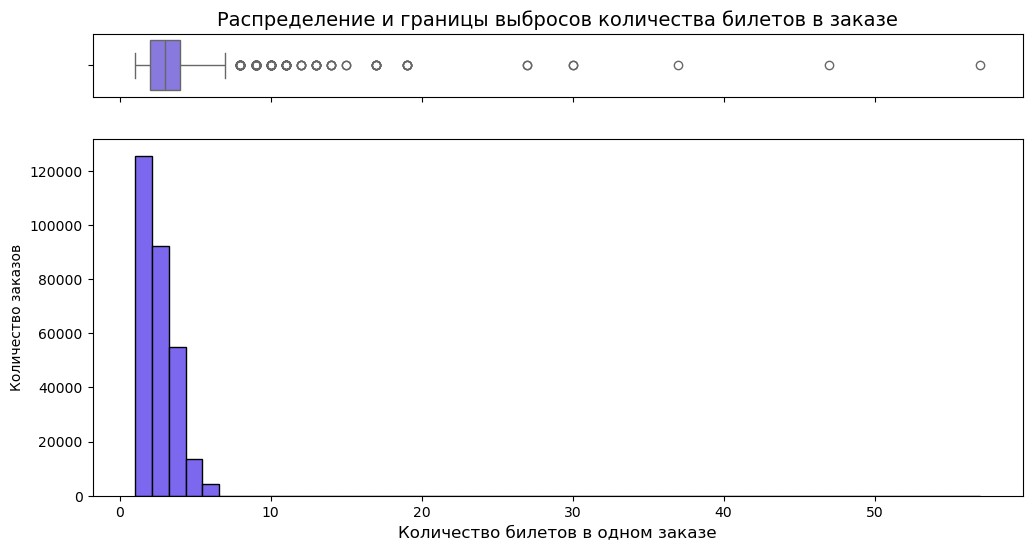

,tickets_count
count,290611.00
mean,2.75
std,1.17
min,1.00
25%,2.00
50%,3.00
75%,4.00
max,57.00


In [18]:
plot_hist_and_box(
    data_series=tickets_df['tickets_count'], 
    title_name='Распределение и границы выбросов количества билетов в заказе', 
    xlabel_name='Количество билетов в одном заказе',
    ylabel_name='Количество заказов'
)


<br>**Вывод по распределению количества билетов**
<br>Анализ графика и числовых характеристик столбца `tickets_count` показывает следующие особенности:
* **Основная масса заказов**: чаще всего пользователи приобретают от 1 до 4 билетов за один раз, при этом медианное значение составляет 3 билета. Это стандартное поведение для обычных покупателей.
* **Выбросы и аномалии**: минимальное значение равно 1, что абсолютно логично. Однако максимальное значение достигает 57 билетов в одном заказе. На графике чётко видно, что после отметки в 6–7 билетов идёт длинный пустой хвост. Такие крупные единичные покупки выглядят нетипично для розничных пользователей и требуют фильтрации на этапе чистки данных, чтобы не искажать общую статистику.

<br>**Далее перейдём к исследованию выручки.** 
<br>Поскольку в наших данных продажи зафиксированы в двух разных валютах — **российских рублях** и **казахстанских тенге**, изучать их распределение в одном общем столбце нецелесообразно из-за разницы в курсах и масштабах стоимости. Мы рассмотрим выручку по каждой валюте последовательно и отдельно: **начнём с распределения заказов в российских рублях**.

<br>*Фильтруем данные для заказов в российских рублях:*

In [19]:
rub_revenue = tickets_df[tickets_df['currency_code'] == 'rub']['revenue']

<br>***Для выручки в российских рублях (`rub`)** строим совмещенный график и выводим статистику с помощтю функции:*

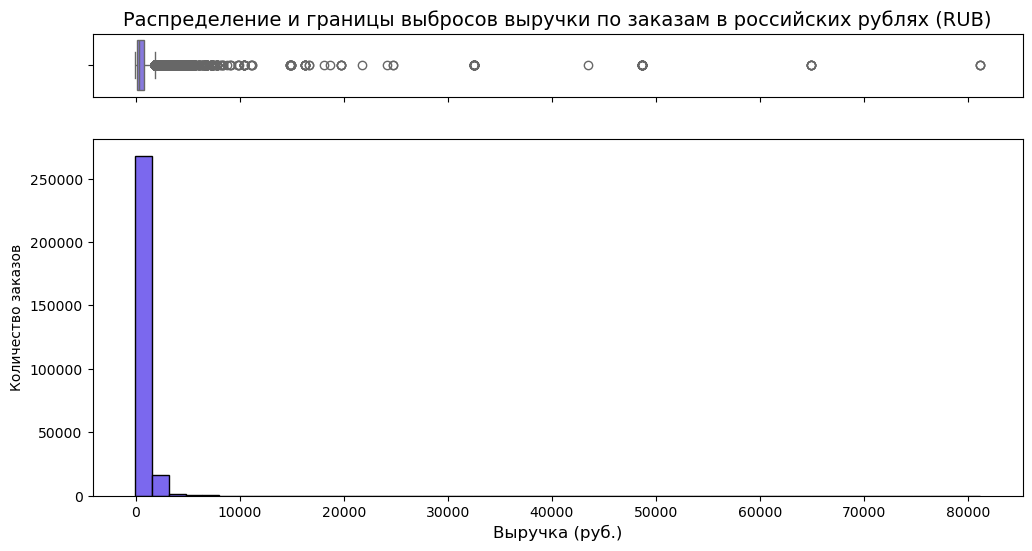

,revenue
count,285542.00
mean,548.01
std,871.75
min,-90.76
25%,114.17
50%,346.63
75%,793.32
max,81174.54


In [20]:
plot_hist_and_box(
    data_series=rub_revenue, 
    title_name='Распределение и границы выбросов выручки по заказам в российских рублях (RUB)', 
    xlabel_name='Выручка (руб.)',
    ylabel_name='Количество заказов'
)


<br>**Вывод по распределению выручки в рублях (`RUB`)**
<br>Анализ графика и статистических показателей выручки по заказам в российских рублях указывает на следующие важные особенности:
* **Основной диапазон**: половина всех заказов не превышает сумму в 346.63 руб. (медианное значение), а 75% покупок укладываются в лимит до 793.32 руб. Это свидетельствует о том, что большинство пользователей выбирают недорогие билеты.
* **Аномалии и выбросы**: в данных присутствует явная техническая или экономическая ошибка — минимальная выручка составляет отрицательное значение (-90.76 руб.). Экономически это может быть связано с оформлением возврата билетов. Так как цель нашего проекта — изучить именно чистые продажи и покупательскую активность, эти строки будут занижать средние чеки. В то же время максимальный чек достигает 81 174.54 руб. Из-за этого единичного сверхкрупного выброса вся гистограмма оказалась сильно прижата к левому краю. Эти аномалии обязательно нужно отфильтровать на этапе чистки данных.

<br>**Распределение выручки по заказам в казахстанских тенге (`KZT`)**
<br>Теперь аналогичным образом исследуем показатели выручки для заказов, оформленных в казахстанских тенге, чтобы оценить форму их распределения и проверить наличие подобных скрытых ошибок.

<br>*Фильтруем данные для заказов в тенге:*

In [21]:
kzt_revenue = tickets_df[tickets_df['currency_code'] == 'kzt']['revenue']

<br>***Для выручки в казахстанских тенге (`kzt`)** строим совмещенный график и выводим статистику с помощтю функции:*

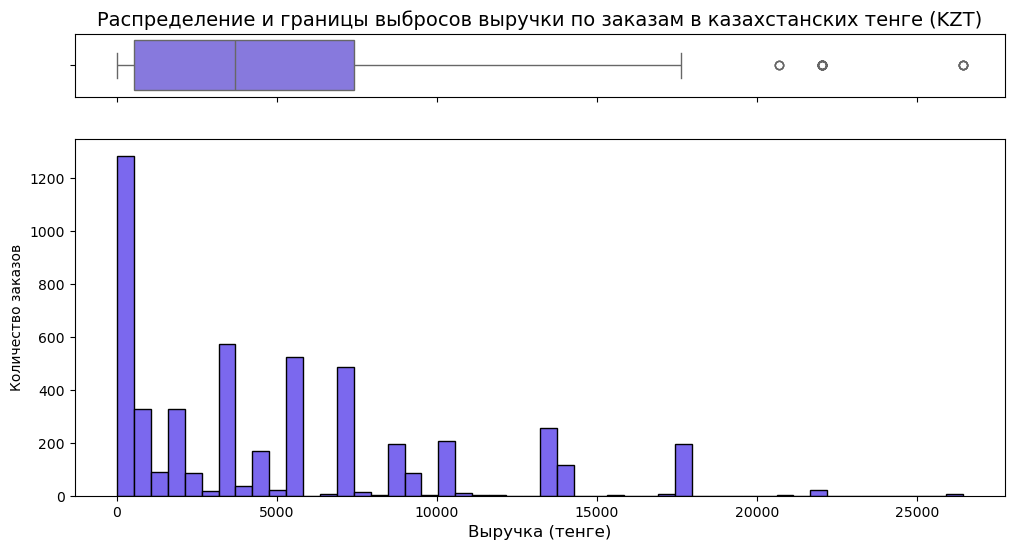

,revenue
count,5069.00
mean,4995.21
std,4916.75
min,0.00
25%,518.10
50%,3698.83
75%,7397.66
max,26425.86


In [22]:
plot_hist_and_box(
    data_series=kzt_revenue, 
    title_name='Распределение и границы выбросов выручки по заказам в казахстанских тенге (KZT)', 
    xlabel_name='Выручка (тенге)',
    ylabel_name='Количество заказов'
)


<br>**Вывод по распределению выручки в тенге (KZT)**
<br>Анализ числовых характеристик и формы распределения выручки по заказам в казахстанских тенге показывает следующие особенности:
* **Основной диапазон**: половина заказов не превышает сумму в 3 698.83 тенге, а 75% всех покупок укладываются в лимит до 7 397.66 тенге. Распределение имеет более выраженную ступенчатую форму, чем в рублях, но общая тенденция сохраняется — большинство пользователей предпочитает билеты из бюджетного и среднего ценового сегмента.
* **Аномалии и выбросы**: минимальная выручка равна 0.00 тенге, что может указывать на использование стопроцентных промокодов, акций или технические особенности учёта. Максимальный чек достигает 26 425.86 тенге, формируя длинный правый хвост на графике.

<br>

#### <a id="p2_2_3"></a> **Расчёт границ для удаления выбросов**
<br>Чтобы убрать нетипичные крупные заказы и аномально высокие чеки, которые растягивают наши графики и мешают расчётам, определим точные математические границы. Для этого рассчитаем 99-й процентиль для количества билетов в одном заказе, а также для выручки в рублях и тенге отдельно. Всё, что окажется выше этих значений (крайний 1% самых экстремальных данных), мы отсечём на этапе фильтрации.

<br>*Рассчитаем 99-й процентиль для количества билетов и выручки по валютам, выведя результат на экран:*

In [23]:
quantile_tickets = tickets_df['tickets_count'].quantile(0.99)
quantile_rub = tickets_df[tickets_df['currency_code'] == 'rub']['revenue'].quantile(0.99)
quantile_kzt = tickets_df[tickets_df['currency_code'] == 'kzt']['revenue'].quantile(0.99)

print(f"99-й процентиль для количества билетов: {quantile_tickets}")
print(f"99-й процентиль для выручки в рублях (RUB): {quantile_rub:.2f}")
print(f"99-й процентиль для выручки в тенге (KZT): {quantile_kzt:.2f}")


99-й процентиль для количества билетов: 6.0
99-й процентиль для выручки в рублях (RUB): 2570.80
99-й процентиль для выручки в тенге (KZT): 17617.24


<br>**Итог расчёта процентилей**
<br>На основе 99-го процентиля определены конкретные верхние границы для очистки данных от выбросов:
* **Количество билетов**: не более 6 штук в одном заказе.
* **Выручка в рублях (RUB)**: не более 2 570.80 рублей.
* **Выручка в тенге (KZT)**: не более 17 617.24 тенге.

Все заказы, превышающие эти лимиты, составляют крайний 1% экстремальных значений и будут отфильтрованы на этапе чистки данных, чтобы не искажать результаты дальнейшего анализа.

<br>

### <a id="p2_3"></a> Проверка данных на явные и неявные дубликаты

Проверим датафрейм на наличие полных дубликатов строк, а также на наличие неявных повторов, когда билеты на одно и то же мероприятие бронировались в одну и ту же секунду, одним пользователем (проверим уникальные комбинации: пользователь + время заказа + ID мероприятия).

<br>*Считаем количество полных дубликатов по номеру заказа:*

In [24]:
order_duplicates = tickets_df.duplicated(subset=['order_id']).sum()

*Считаем количество полных явных дубликатов строк:*

In [25]:
full_duplicates = tickets_df.duplicated().sum()

*Считаем дубликаты по бронированию на одно мероприятие в одно время одним пользователем:*

In [26]:
booking_duplicates = tickets_df.duplicated(subset=['user_id', 'created_ts_msk', 'event_id']).sum()

*Выводим результаты проверки на дубликаты:*

In [27]:
print(f"Всего строк в таблице: {tickets_df.shape[0]}")
print(f"Уникальных номеров заказов (order_id): {tickets_df['order_id'].nunique()}")
print(f"Количество дубликатов по order_id: {order_duplicates}")
print(f"Количество полных явных дубликатов: {full_duplicates}")
print(f"Количество неявных дубликатов бронирования: {booking_duplicates}")

Всего строк в таблице: 290611
Уникальных номеров заказов (order_id): 290611
Количество дубликатов по order_id: 0
Количество полных явных дубликатов: 0
Количество неявных дубликатов бронирования: 120


<br>**Вывод по результатам поиска дубликатов**
<br>В ходе проверки датафрейма полных явных дубликатов строк не обнаружено (0 шт.). Однако выявлено 120 неявных дубликатов бронирования, при которых один и тот же пользователь в одну и ту же секунду оформлял билеты на одно и то же мероприятие. Данные повторы могут быть связаны с техническими сбоями или повторными кликами пользователей, поэтому их необходимо удалить для обеспечения точности дальнейших расчётов.

<br>*Удаляем неявные дубликаты бронирований, сохраняя только первое появление:*

In [28]:
tickets_df = tickets_df.drop_duplicates(subset=['user_id', 'created_ts_msk', 'event_id'], keep='first').reset_index(drop=True)

<br>**Итог обработки дубликатов**
<br>Выявленные 120 неявных повторов успешно удалены из датафрейма. Индексы строк пересчитаны, данные полностью очищены от дублирующих бронирований, но здесь есть важный нюанс.

Так как эти удаленные строки находились внутри цепочек заказов, от них напрямую зависел расчетный столбец `days_since_prev`. Чтобы восстановить идеальную точность и не плодить мелкие технические ошибки в хронологии, этот признак нужно обновить.
<br>Мы обязательно пересчитаем его заново чуть позже — на этапе изменения типов данных, как только переведем столбцы со временем в полноценный формат даты и времени. А пока датасет полностью готов к следующему шагу предобработки.

<br>

### <a id="p2_4"></a> Изменение типов данных для работы с хронологией

Приведём строковые поля с временными метками к корректному формату даты и времени. Это необходимо для корректного выделения временных интервалов и анализа сезонности на этапе исследовательского анализа данных. 

Кроме того, здесь же мы выполним технический пересчёт признака времени между заказами (`days_since_prev`). Так как на предыдущем шаге мы удалили неявные дубликаты, важно обновить эту метрику по очищенным данным, чтобы восстановить идеальную точность цепочек продаж. Всю остальную оптимизацию памяти и сжатие типов мы проведём позже — в самом конце предобработки, когда датасет будет полностью сформирован.


<br>*Переводим временные метки в формат datetime:*

In [29]:
tickets_df['created_dt_msk'] = pd.to_datetime(tickets_df['created_dt_msk'])
tickets_df['created_ts_msk'] = pd.to_datetime(tickets_df['created_ts_msk'])

*Пересчитываем разницу дней между заказами после удаления дубликатов:*

In [30]:
tickets_df = tickets_df.sort_values(by=['user_id', 'created_ts_msk']).reset_index(drop=True)
tickets_df['days_since_prev'] = tickets_df.groupby('user_id')['created_ts_msk'].diff().dt.total_seconds() / 86400.0


*Проверяем получившиеся типы данных:*

In [31]:
tickets_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290491 entries, 0 to 290490
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                290491 non-null  int64         
 1   user_id                 290491 non-null  object        
 2   created_dt_msk          290491 non-null  datetime64[ns]
 3   created_ts_msk          290491 non-null  datetime64[ns]
 4   event_id                290491 non-null  int64         
 5   cinema_circuit          290491 non-null  object        
 6   age_limit               290491 non-null  int64         
 7   currency_code           290491 non-null  object        
 8   device_type_canonical   290491 non-null  object        
 9   revenue                 290491 non-null  float64       
 10  service_name            290491 non-null  object        
 11  tickets_count           290491 non-null  int64         
 12  total                   290491

<br>**Вывод по результатам изменения типов данных:**
<br>Временные метки `created_dt_msk` и `created_ts_msk` успешно переведены в целевой тип `datetime64`. Это открывает возможность для корректного слияния с таблицей курсов валют на следующем шаге. Также мы успешно обновили метрику `days_since_prev` по чистым данным — теперь хронология покупок пользователей рассчитана без учёта удалённых технических дубликатов. Датасет готов к созданию новых расчётных признаков.

<br>

### <a id="p2_5"></a> Создание новых признаков

Для проведения полноценного исследовательского анализа дополним датафрейм новыми расчетными столбцами. На основе таблицы курсов валют переведем всю выручку в единую валюту — российский рубль, рассчитаем выручку с продажи одного билета на мероприятие, а также выделим временные промежутки (месяц и сезон) для оценки сезонности продаж.

#### <a id="p2_5_1"></a> Приведение выручки к единой валюте (российскому рублю)

Для перевода финансовых показателей в единую валюту объединим основной датафрейм `tickets_df` со справочником курсов `tenge_df`. Слияние проведём по полям дат (`created_dt_msk` и `data`) методом `how='left'`. С помощью метода `.loc` создадим новый столбец `revenue_rub`: для заказов в казахстанских тенге запишем результат конвертации с учётом ежедневного курса и номинала, а для заказов в российских рублях просто скопируем исходное значение выручки.

<br>*Сначала приведём столбец даты в `tenge_df` к типу `datetime` для точного слияния:*

In [32]:
tenge_df['data'] = pd.to_datetime(tenge_df['data'])

<br>**Проведём предварительную валидацию справочника курсов валют `tenge_df` перед его объединением с основным датафреймом.**
<br>Нам необходимо убедиться в отсутствии дубликатов по датам (чтобы избежать искусственного задвоения строк при слиянии), проверить адекватность числовых значений курса, зафиксировать используемый номинал и подтвердить, что временной интервал полностью покрывает период нашего исследования.

*Проверим таблицу курсов `tenge_df` на дубликаты и на аномальные значения в курсах, названии валют и временном интервале:*

In [33]:
print("Количество дубликатов по датам:", tenge_df['data'].duplicated().sum())
print("\nСтатистика по курсу валюты:")
print(tenge_df['curs'].describe()) 
print("\nУникальные валюты в таблице:", tenge_df['cdx'].unique())
print("\nУникальный номинал в таблице:", tenge_df['nominal'].unique())
print(f"\nПериод курсов валют: с {tenge_df['data'].min()} по {tenge_df['data'].max()}")


Количество дубликатов по датам: 0

Статистика по курсу валюты:
count    357.000000
mean      19.755818
std        0.833798
min       17.848600
25%       19.120200
50%       19.876000
75%       20.443300
max       21.937100
Name: curs, dtype: float64

Уникальные валюты в таблице: ['kzt']

Уникальный номинал в таблице: [100]

Период курсов валют: с 2024-01-10 00:00:00 по 2024-12-31 00:00:00


<br>**Анализ результатов проверки справочника валют:**
* **Чистота ключей:** Дубликаты по датам полностью отсутствуют (выявлено 0 повторов), что гарантирует безопасность проведения операции `merge`.
* **Адекватность данных:** Значения курса стабильны (среднее значение ~19.75 рублей за 100 тенге), аномальных выбросов или нулевых значений не обнаружено. Валюта представлена исключительно кодом `kzt` с единым номиналом `100`.
* **Временной охват:** Данные покрывают весь период с января по декабрь 2024 года, что полностью соответствует хронологии наших заказов.

Проверка подтвердила абсолютную корректность и полноту данных. Препятствий для слияния нет — переходим к объединению датафреймов по датам.


<br>*Объединяем основной датафрейм со справочником курсов валют по датам:*

In [34]:
tickets_df = tickets_df.merge(tenge_df, left_on='created_dt_msk', right_on='data', how='left')

<br>*Создаём новый столбец с выручкой в рублях, применим векторный метод `.where()`:* 
<br>Если код валюты равен `rub`, метод оставит исходное значение выручки, а во всех остальных случаях (для тенге) автоматически применит математическую формулу конвертации с учётом курса и номинала из справочника.

In [35]:
tickets_df['revenue_rub'] = tickets_df['revenue'].where(tickets_df['currency_code'] == 'rub', 
                                                        (tickets_df['revenue'] * tickets_df['curs']) / tickets_df['nominal'])

*Проверяем результат: выводим строки, где валюта строго тенге ('kzt'):*

In [36]:
display(tickets_df[tickets_df['currency_code'] == 'kzt'][['currency_code', 'revenue', 'curs', 'nominal', 'revenue_rub']].head())


,currency_code,revenue,curs,nominal,revenue_rub
70,kzt,518.10,19.0125,100,98.503762
89,kzt,347.18,18.9330,100,65.731589
96,kzt,328.77,18.5991,100,61.148261
277,kzt,22021.55,19.8928,100,4380.702898
460,kzt,3698.83,19.9833,100,739.148295


<br>**Удаление технических столбцов после конвертации валют**
<br>Поскольку расчёт выручки в единой валюте успешно завершён, удалим из датафрейма вспомогательные столбцы, полученные из справочника курсов (`data`, `nominal`, `curs`, `cdx`). Это позволит очистить таблицу от дублирующей и лишней информации перед созданием следующих аналитических признаков.

<br>*Удаляем технические столбцы по их названиям:*

In [37]:
tickets_df = tickets_df.drop(columns=['data', 'nominal', 'curs', 'cdx'])

*Проверим результат, выведя общую информацию `.info()` о датасете `tickets_df`:*

In [38]:
tickets_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290491 entries, 0 to 290490
Data columns (total 25 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                290491 non-null  int64         
 1   user_id                 290491 non-null  object        
 2   created_dt_msk          290491 non-null  datetime64[ns]
 3   created_ts_msk          290491 non-null  datetime64[ns]
 4   event_id                290491 non-null  int64         
 5   cinema_circuit          290491 non-null  object        
 6   age_limit               290491 non-null  int64         
 7   currency_code           290491 non-null  object        
 8   device_type_canonical   290491 non-null  object        
 9   revenue                 290491 non-null  float64       
 10  service_name            290491 non-null  object        
 11  tickets_count           290491 non-null  int64         
 12  total                   290491

<br>**Вывод по результатам добавления нового столбца**
<br>Новое поле с выручкой в единой валюте `revenue_rub` успешно рассчитано и добавлено в датафрейм. Контрольная проверка информации о таблице подтверждает, что столбец имеет корректный вещественный тип данных `float64` и полностью заполнен (содержит все 290 491 запись без пропусков), что позволяет использовать его для дальнейших расчётов.

<br>

#### <a id="p2_5_2"></a> Расчёт выручки с продажи одного билета на мероприятие

Для оценки стоимости билетов создадим новый столбец `one_ticket_revenue_rub`. Он рассчитывается построчно для каждого заказа путём деления общей рублёвой выручки `revenue_rub` на количество купленных билетов `tickets_count`.

<br>*Рассчитываем стоимость одного билета в заказе:*

In [39]:
tickets_df['one_ticket_revenue_rub'] = tickets_df['revenue_rub'] / tickets_df['tickets_count']

*Проверим результат, выведя первые 5 строк для контрольных полей:*

In [40]:
display(tickets_df[['tickets_count', 'revenue_rub', 'one_ticket_revenue_rub']].head())

,tickets_count,revenue_rub,one_ticket_revenue_rub
0,4,1521.94,380.4850
1,2,289.45,144.7250
2,4,1258.57,314.6425
3,2,8.49,4.2450
4,3,1390.41,463.4700


<br>**Вывод по результатам расчёта стоимости билета**
<br>Новый признак `one_ticket_revenue_rub` успешно рассчитан и добавлен в датафрейм. Выборочная проверка первых строк подтверждает корректность деления рублевой выручки заказа на количество билетов для каждой записи.

#### <a id="p2_5_3"></a> Выделение месяца оформления заказа

Для исследования сезонности извлечём порядковый номер месяца из столбца `created_dt_msk` и запишем его в новый признак `month`. Это позволит сгруппировать продажи по хронологии и изучить динамику спроса.

<br>*Извлекаем месяц из даты:*

In [41]:
tickets_df['month'] = tickets_df['created_dt_msk'].dt.month

<br>*Проверяем итоговый тип данных и уникальные значения месяца:*

In [42]:
print(f"Итоговый тип данных столбца: {tickets_df['month'].dtype}")
print(f"Уникальные месяцы в датасете: {tickets_df['month'].sort_values().unique()}")

Итоговый тип данных столбца: int32
Уникальные месяцы в датасете: [ 6  7  8  9 10]


<br>**Вывод по результатам выделения месяцев**
<br>Новый столбец `month` успешно создан и оптимизирован до типа `int8`. В результате проверки обнаружено, что датасет содержит информацию о заказах за пять месяцев: с июня по октябрь (номера 6, 7, 8, 9, 10).

#### <a id="p2_5_4"></a> Определение сезона совершения заказа

Для проведения сопоставительного анализа летней и осенней активности покупателей объединим месяцы в соответствующие сезоны. Чтобы код был масштабируемым и стабильно работал наперёд при возможном обновлении базы данных, заложим логику распределения на весь календарный год (включая зиму и весну). С помощью метода `.loc` и фильтрации `.isin()` привяжем каждый месяц к его сезону, после чего преобразуем полученный столбец `season` в оптимизированный тип `category`.

<br>*Размечаем сезоны с учётом всех возможных месяцев года на будущее:*

In [43]:
tickets_df.loc[tickets_df['month'].isin([6, 7, 8]), 'season'] = 'лето'
tickets_df.loc[tickets_df['month'].isin([9, 10, 11]), 'season'] = 'осень'
tickets_df.loc[tickets_df['month'].isin([12, 1, 2]), 'season'] = 'зима'
tickets_df.loc[tickets_df['month'].isin([3, 4, 5]), 'season'] = 'весна'

<br>*Проверяем итоговый тип данных и уникальные значения:*
<br>Используя метод `.tolist()`, чтоб не перезагружать вывод из-за системной строчки категориального типа данных

In [44]:
print(f"Итоговый тип данных столбца: {tickets_df['season'].dtype}")
print(f"Уникальные сезоны в датасете: {tickets_df['season'].unique().tolist()}")

Итоговый тип данных столбца: object
Уникальные сезоны в датасете: ['лето', 'осень']


<br>**Вывод по результатам выделения сезонов**
<br>Новый признак `season` успешно создан. Проверка уникальных значений подтверждает, что на основе имеющихся в датасете месяцев (с июня по октябрь) заказы безошибочно разделились на два целевых аналитических периода — `«лето»` (июнь, июль, август) и `«осень»` (сентябрь, октябрь), что полностью подготавливает датасет к исследованию сезонных изменений.

<br>

### <a id="p2_6"></a> Финальная фильтрация и очистка данных от аномалий

Опираясь на результаты проведённого ранее анализа, проведём итоговую фильтрацию данных перед переходом к исследовательскому анализу, очистив датасет от нетипичных выбросов и ранее обнаруженных аномалий:
1. Отрицательную выручку в российских рублях (которая экономически может означать возвраты билетов).
2. Оптовые заказы, в которых количество билетов превышает установленную границу 99-го процентиля (более 6 штук).
3. Аномально крупные чеки, превышающие границы 99-го процентиля для каждой валюты по отдельности (более 2 570.80 рублей и более 17 617.24 тенге).

После проведения фильтрации проверим, какой объём данных был отобран для дальнейшего исследования.

<br>*Зафиксируем начальное количество строк для расчёта потерь:*

In [45]:
initial_rows = len(tickets_df)

<br>*Применим комплексную фильтрацию к датафрейму, исключив выявленные аномалии по следующим критериям:*
<br>1. Оставим заказы, содержащие не более 6 билетов (граница 99-го процентиля).
<br>2. Удалим записи с отрицательной и нулевой выручкой (возвраты и технические сбои).
<br>3. Ограничим верхнюю стоимость заказов по 99-му процентилю раздельно для каждого рынка: до 2 570.80 рублей для РФ и до 17 617.24 тенге для Казахстана.

In [46]:
tickets_df = tickets_df[
    (tickets_df['tickets_count'] <= quantile_tickets) & 
    (tickets_df['revenue'] > 0) & 
    (
        ((tickets_df['currency_code'] == 'rub') & (tickets_df['revenue'] <= quantile_rub)) | 
        ((tickets_df['currency_code'] == 'kzt') & (tickets_df['revenue'] <= quantile_kzt))
    )
].reset_index(drop=True)

<br>*Считаем результаты фильтрации:*

In [47]:
final_rows = len(tickets_df)
rows_lost = initial_rows - final_rows
percent_lost = (rows_lost / initial_rows) * 100

<br>*Выводим результаты на экран:*

In [48]:
print(f"Строк до фильтрации: {initial_rows}")
print(f"Строк после фильтрации: {final_rows}")
print(f"Удалено аномальных строк: {rows_lost} ({percent_lost:.2f}%)")

Строк до фильтрации: 290491
Строк после фильтрации: 281590
Удалено аномальных строк: 8901 (3.06%)


<br>

#### <a id="p2_6_1"></a> Оптимизация памяти и финальное приведение типов

<br>*Но перед этим выведем `info()` по получившемуся датасету `tickets_df`, чтоб зафиксировать сколько изначально занимает объём оперативной памяти `memory usage`:*

In [49]:
tickets_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 281590 entries, 0 to 281589
Data columns (total 28 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                281590 non-null  int64         
 1   user_id                 281590 non-null  object        
 2   created_dt_msk          281590 non-null  datetime64[ns]
 3   created_ts_msk          281590 non-null  datetime64[ns]
 4   event_id                281590 non-null  int64         
 5   cinema_circuit          281590 non-null  object        
 6   age_limit               281590 non-null  int64         
 7   currency_code           281590 non-null  object        
 8   device_type_canonical   281590 non-null  object        
 9   revenue                 281590 non-null  float64       
 10  service_name            281590 non-null  object        
 11  tickets_count           281590 non-null  int64         
 12  total                   281590

<br>Понижаем разрядность для целых и вещественных чисел.
<br>Для этого *создаём два отдельных соответсвующих списка:*

In [50]:
int_columns = ['order_id', 'event_id', 'tickets_count', 'days_since_prev', 'city_id', 'venue_id', 'month']
float_columns = ['revenue', 'total', 'days_since_prev', 'revenue_rub', 'one_ticket_revenue_rub']

<br>*Создаём циклы для каждого списка с использованием `downcast`:*

In [51]:
for col in int_columns:
    tickets_df[col] = pd.to_numeric(tickets_df[col], downcast='integer')

for col in float_columns:
    tickets_df[col] = pd.to_numeric(tickets_df[col], downcast='float')

<br>Переводим стабильные текстовые признаки в тип `category` для максимального сжатия памяти.
<br>*Создаём список со всеми возможными категориальными полями:*

In [52]:
category_columns = ['cinema_circuit', 'age_limit', 'currency_code', 'device_type_canonical', 'service_name', 
                    'event_type_description', 'event_type_main', 'region_name', 'city_name', 'season']

*Создаём цикл, который преобразует список текстовых полей к типу `category`:*

In [53]:
for col in category_columns:
    tickets_df[col] = tickets_df[col].astype('category')

*Проверяем итоговые типы данных и экономию памяти:*

In [54]:
tickets_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 281590 entries, 0 to 281589
Data columns (total 28 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                281590 non-null  int32         
 1   user_id                 281590 non-null  object        
 2   created_dt_msk          281590 non-null  datetime64[ns]
 3   created_ts_msk          281590 non-null  datetime64[ns]
 4   event_id                281590 non-null  int32         
 5   cinema_circuit          281590 non-null  category      
 6   age_limit               281590 non-null  category      
 7   currency_code           281590 non-null  category      
 8   device_type_canonical   281590 non-null  category      
 9   revenue                 281590 non-null  float32       
 10  service_name            281590 non-null  category      
 11  tickets_count           281590 non-null  int8          
 12  total                   281590

<br>**Вывод по результатам изменения типов данных и оптимизации памяти**
<br>Преобразование форматов и оптимизация разрядности признаков успешно завершены. На основе финальной информации о датафрейме можно сделать следующие выводы:
* **Формат даты и времени**: столбцы `created_dt_msk` и `created_ts_msk` успешно переведены в целевой тип `datetime64`. Это открывает возможность для корректной стыковки с третьей таблицей курсов валют и последующего анализа сезонности по временным интервалам.
* **Числовые и категориальные признаки**: идентификаторы `order_id`, `event_id`, `city_id` и `venue_id`, а также количество купленных билетов `tickets_count` и количество дней `days_since_prev` приведены к компактным целочисленным типам (`int8`, `int16`, `int32`). Ключевые текстовые поля с фиксированным набором значений переведены в тип `category`. Столбец `user_id` сохранён в исходном строковом формате `object`, так как его значения содержат буквенные символы.
* **Эффективность оптимизации**: благодаря снижению разрядности чисел и использованию категориального типа данных объём занимаемой датафреймом оперативной памяти сократился более чем в два раза — с 59.1+ MB до 28.8+ MB.

<br>

#### <a id="p2_6_2"></a> Общий промежуточный вывод по этапу предобработки данных

Этап предобработки и подготовки данных к исследовательскому анализу успешно завершён. В ходе выполнения этого шага были проделаны следующие операции:

1. **Обработка пропусков и дубликатов**: удалено 238 строк (0.08%), в которых отсутствовала привязка к справочнику мероприятий. Пропуски в поле количества дней с предыдущей покупки `days_since_prev` (7.54%) оставлены без изменений, так как в ходе анализа было математически подтверждено их естественное происхождение (они строго соответствуют первой покупке каждого пользователя на сервисе). Также стёрты 120 неявных дубликатов повторного бронирования.
2. **Финальная фильтрация**: на основе рассчитанных 99-х процентилей датасет очищен от экстремальных выбросов по стоимости, оптовых заказов (более 6 билетов) и транзакций с отрицательной выручкой (возвратов). Итоговый массив содержит 281 590 строк. Суммарный объём удалённых аномалий составил всего 3.06%, что полностью безопасно для точности исследования.
3. **Преобразование типов данных**: строковые поля с датами переведены в формат `datetime64`. Для числовых признаков выполнено понижение разрядности (downcast), а стабильные текстовые признаки упакованы в тип `category`. Это позволило сократить объём оперативной памяти, занимаемой датафреймом, более чем в два раза — с 59.1+ MB до 28.8+ MB.

В процессе работы в итоговую таблицу `tickets_df` были добавлены новые расчетные признаки, необходимые для дальнейшего анализа:
* `revenue_rub` — конечная выручка от продажи билетов, приведённая к единой валюте (российскому рублю) на основе ежедневных курсов из справочника валют;
* `one_ticket_revenue_rub` — стоимость одного билета в рамках конкретного заказа;
* `month` — порядковый номер месяца совершения покупки для оценки ежемесячной динамики;
* `season` — категориальный признак временного периода, гибко разделяющий заказы по календарным сезонам («лето», «осень», «зима», «весна») для оценки изменений спроса во времени.

Данные полностью очищены от ошибок, оптимизированы и готовы к проведению исследовательского анализа.

## <a id="p3"></a> Исследовательский анализ данных

### <a id="p3_1"></a> Анализ распределения заказов по сегментам и их сезонных изменений

В данном разделе исследуем, как меняется количество заказов и интерес пользователей к билетам в зависимости от месяца, типа мероприятия, типа устройства и возрастного рейтинга. Это поможет понять, в какое время года определенные категории событий пользуются наибольшим спросом.

#### <a id="p3_1_1"></a> Динамика количества заказов по месяцам

Начнём исследование с анализа общей динамики спроса. Сгруппируем данные по месяцам, посчитаем общее количество уникальных оформленных заказов для каждого из них и визуализируем результаты на линейном графике. Это позволит проверить растёт ли покупательская активность от июня к октябрю 2024 года.

<br>*Создаём серию с количеством уникальных заказов по каждому месяцу:*

In [55]:
orders_by_month = tickets_df.groupby('month')['order_id'].nunique()

*Строим линейный график динамики заказов по месяцам:*
<br>Создаём контейнер для графика и задаём его размер:

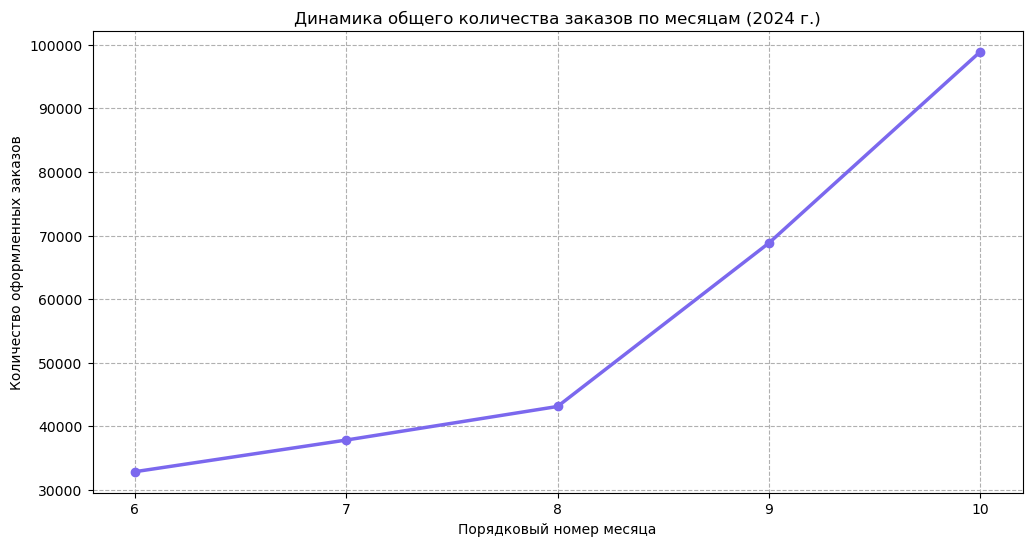


Число уникальных заказов по месяцам:


month
6     32866
7     37845
8     43128
9     68831
10    98920
Name: order_id, dtype: int64

In [56]:
plt.figure(figsize=(12, 6))

orders_by_month.plot(
    kind='line',
    marker='o',
    linewidth=2.5,
    color='mediumslateblue',
    title='Динамика общего количества заказов по месяцам (2024 г.)'
)

# Настраиваем оформление графика:
plt.xlabel('Порядковый номер месяца')
plt.ylabel('Количество оформленных заказов')
plt.xticks(orders_by_month.index) # Отображаем на оси X только имеющиеся месяцы (6, 7, 8, 9, 10)

# Добавим сетку:
plt.grid(True, linestyle='--')

# Выводим график:
plt.show()

# Выведем таблицу со значениями для лучшей интерпретации вывода:
print("\nЧисло уникальных заказов по месяцам:")
display(orders_by_month)


<br>**Вывод по результатам анализа ежемесячной динамики заказов**
<br>Построенный линейный график и численные результаты группировки позволяют сделать следующие выводы:
* **Общий тренд**: на протяжении всего исследуемого периода (с июня по октябрь 2024 года) фиксируется непрерывный и стабильный рост количества оформленных заказов.
* **Летний период**: в летние месяцы (июнь–август) активность покупателей увеличивается умеренными темпами — с 32 866 заказов в июне до 43 128 в августе.
* **Осенний период**: начиная с сентября наблюдается резкий скачок покупательской активности. В сентябре число заказов увеличивается до 68 831, а в октябре достигает пикового значения — 98 920 заказов. 

Таким образом, предположение о выраженном увеличении количества заказов от июня к осени 2024 года полностью подтверждается. Осенний сезон характеризуется кратным ростом спроса на билеты по сравнению с началом лета.

<br>

#### <a id="p3_1_2"></a> Сравнение распределения заказов летом и осенью

В этом разделе мы сравним, как распределяются заказы в летний и осенний периоды **`по типам мероприятий`**, **`устройствам`** и **`возрастным ограничениям`**. Чтобы изменения в объемах продаж между сезонами не искажали картину, для анализа мы будем использовать доли, а не абсолютные показатели.

<br>**Создадим функцию для сезонного анализа категориальных признаков**

Для комплексного изучения структуры заказов в летний и осенний периоды напишем универсальную функцию `plot_seasonal_distribution`. Она автоматизирует расчеты и визуализацию для каждого анализируемого признака по следующему алгоритму:

1. **Расчет относительных долей:** Группирует данные по сезонам (`season`) и вычисляет процентное соотношение категорий отдельно внутри лета и отдельно внутри осени. Это позволяет увидеть чистый структурный сдвиг в предпочтениях клиентов.
2. **Визуализация:** Строит горизонтальный столбчатый график (`barh`), на котором начало оси X строго зафиксировано на нуле (`0`), чтобы избежать искажения масштабов.
3. **Вывод данных:** Формирует и выводит итоговую таблицу с точными расчетами сразу под графиком.
<br>

In [57]:
def plot_seasonal_distribution(column_name, category):
    # Считаем доли категорий внутри каждого сезона:
    seasonal_data = tickets_df.groupby('season', observed=False)[column_name].value_counts(normalize=True).unstack(level=0) * 100
    
    # Сортируем по убыванию осенних показателей
    seasonal_data = seasonal_data.sort_values(by='осень', ascending=False)
    
    # Строим горизонтальный график (barh)
    # .iloc[::-1] нужен, чтобы топ-категории отображались сверху вниз
    seasonal_data.iloc[::-1].plot(
        kind='barh',
        figsize=(12, 6),
        color=['teal', 'lightcoral'],
        title=f"Распределение заказов по категориям: {category} (Лето vs Осень)"
    )
    
    # Настраиваем оформление для горизонтального графика
    plt.ylabel(category)
    plt.xlabel('Доля внутри сезона (%)')
    plt.xlim(0, None) 
    plt.legend(title='Сезон')
    plt.grid(axis='x', linestyle='--')
    
    # Выводим график
    plt.show()
    
    # Выводим таблицу под графиком
    print("\nРаспределение долей внутри сезонов (%):")
    display(seasonal_data.round(2))


<br>**Распределение заказов в летний и осенний периоды `по типам мероприятий`**

*Применим созданную функцию к столбцу `event_type_main`, чтобы рассчитать доли различных типов мероприятий внутри каждого сезона, построить сравнительный график и вывести таблицу с точными результатами:*

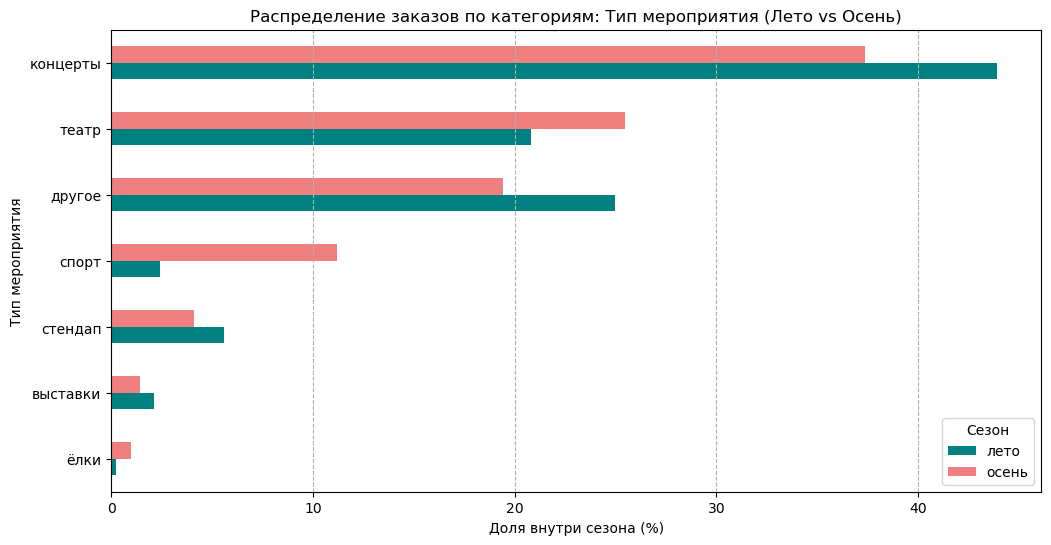


Распределение долей внутри сезонов (%):


season,лето,осень
event_type_main,,
концерты,43.90,37.38
театр,20.80,25.45
другое,24.95,19.43
спорт,2.42,11.18
стендап,5.57,4.13
выставки,2.11,1.43
ёлки,0.24,1.01


In [58]:
plot_seasonal_distribution('event_type_main', 'Тип мероприятия')


<br>**Вывод по результатам анализа распределения типов мероприятий по сезонам**
<br>Анализ относительных долей категорий внутри каждого сезона позволил выявить реальные структурные изменения в предпочтениях аудитории при переходе от лета к осени, выделив категории с разным характером сезонного спроса:
* **Стабильные лидеры спроса:** Категория **`«концерты»`** остается главным направлением в течение всего исследуемого периода. При этом летом их доля в структуре заказов достигает максимума (43.90%), а осенью немного снижается (до 37.38%), уступая часть рынка другим сезонным событиям.
* **Категории с осенним ростом (повышенный спрос):** Наиболее выраженный сезонный сдвиг зафиксирован в сегментах **`«театр»`** и **`«спорт»`**. Доля театральных заказов осенью выросла с 20.80% до 25.45%. Спортивные события показали самый мощный относительный скачок — их доля в структуре продаж увеличилась с 2.42% летом до 11.18% осенью (почти в 4.6 раза), что явно связано со стартом новых спортивных сезонов. Также наметился рост в сегменте **`«ёлки»`** (с 0.24% до 1.01%) из-за запуска ранних осенних предпродаж.
* **Категории со спадом интереса к осени:** Сегменты **`«другое»`** (снижение с 24.95% до 19.43%), **`«стендап»`** (с 5.57% до 4.13%) и **`«выставки»`** (с 2.11% до 1.43%) в осенний период теряют свои позиции в общем объеме заказов, уступая лидирующим сезонным направлениям.

<br><br>**Распределение заказов в летний и осенний периоды `по типам устройств`**

*Применим созданную функцию к столбцу `device_type_canonical`, чтобы проанализировать, меняется ли предпочтительный способ заказа билетов у пользователей при смене сезонов:*

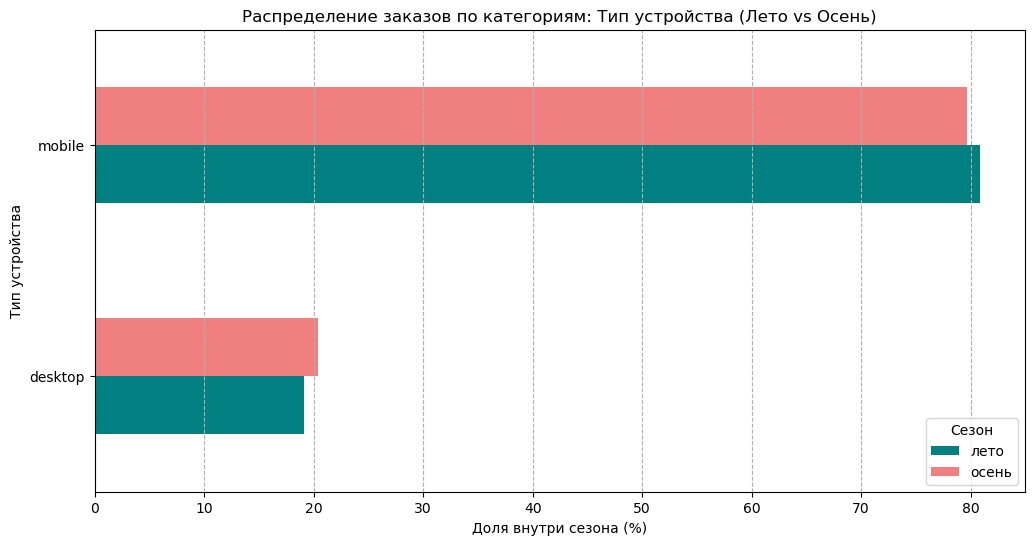


Распределение долей внутри сезонов (%):


season,лето,осень
device_type_canonical,,
mobile,80.9,79.62
desktop,19.1,20.38


In [59]:
plot_seasonal_distribution('device_type_canonical', 'Тип устройства')


<br>**Вывод по результатам анализа типов устройств:**
<br>Анализ используемых платформ показывает высокую стабильность пользовательских предпочтений вне зависимости от времени года:

* **Абсолютный лидер:** Покупки через мобильные устройства **`mobile`** составляют основу продаж в оба сезона. Летом их доля достигает 80.90%, а осенью незначительно снижается до 79.62%. Смартфоны остаются ключевым каналом взаимодействия с клиентами.
* **Стабильный десктоп:** Заказы через компьютеры и ноутбуки **`desktop`** занимают меньшую, но стабильную долю рынка. С переходом на осенний период фиксируется минимальный прирост их популярности — с 19.10% летом до 20.38% осенью. 

В целом структура каналов продаж не подвержена сезонным колебаниям, и мобильный трафик удерживает подавляющее преимущество в течение всего исследуемого периода.

<br><br>**Распределение заказов в летний и осенний периоды `по возрастным рейтингам`**

*Применим функцию к столбцу `age_limit`, чтобы изучить изменения в возрастной структуре спроса на билеты при переходе от летнего сезона к осеннему:*

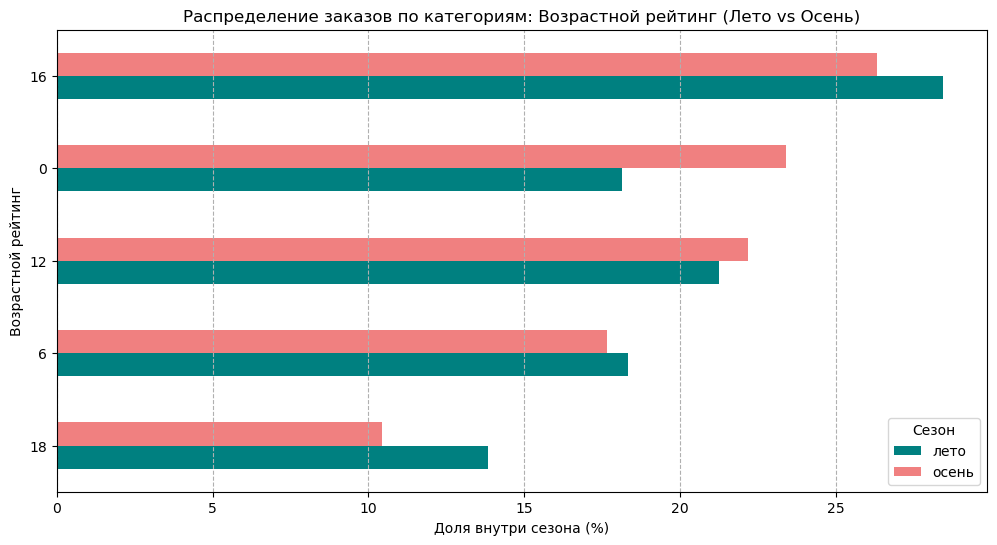


Распределение долей внутри сезонов (%):


season,лето,осень
age_limit,,
16,28.44,26.34
0,18.13,23.40
12,21.25,22.18
6,18.34,17.65
18,13.84,10.43


In [60]:
plot_seasonal_distribution('age_limit', 'Возрастной рейтинг')


<br>**Вывод по результатам анализа возрастных рейтингов:**
<br>Анализ структуры заказов по возрастным ограничениям выявил заметное перераспределение спроса между семейным и взрослым контентом:
* **Лидер структуры:** Возрастной рейтинг **`«16+»`** занимает самую большую долю рынка в оба сезона. При этом летом его позиции сильнее — 28.44%, а к осени доля снижается до 26.34%.
* **Явный осенний рост:** Наиболее значительное изменение зафиксировано в сегменте **`«0+»`**. Осенью его доля в структуре заказов подскочила с 18.13% до 23.40% (рост более чем на 5%), что вывело категорию на второе место и указывает на резкое увеличение спроса на детские и семейные мероприятия. Также небольшой рост показал рейтинг **`«12+»`** — с 21.25% летом до 22.18% осенью.
* **Сезонный спад «взрослого» сегмента:** Наряду со снижением рейтинга «16+», заметное падение доли демонстрирует категория **«18+»** — её присутствие в структуре продаж сократилось с 13.84% летом до 10.43% осенью. Сегмент **«6+»**, который летом занимал почётное второе место (из 5-ти возрастных категорий) — теперь на предпоследнем месте (на 4-м) также показал минимальное снижение (с 18.34% до 17.65%).

В целом осенний период характеризуется смещением фокуса аудитории в сторону универсальных семейных («0+» и «12+») событий, в то время как востребованность строго возрастных мероприятий («16+» и «18+») в общем объеме продаж снижается.

<br>

#### <a id="p3_1_3"></a> Изучение изменения выручки с продажи одного билета по типам мероприятий

В этом подразделе мы рассчитаем среднюю стоимость одного билета для каждого типа мероприятия летом и осенью. Затем мы найдем относительное изменение осенних цен по сравнению с летними и построим график, чтобы наглядно увидеть динамику среднего чека.

Для корректного определения средней стоимости одного билета сгруппируем данные по типам мероприятий и сезонам. Расчет выполним путем деления суммарной выручки каждого сегмента на общее количество проданных билетов. Данный подход позволяет получить объективную среднюю цену и исключает математические искажения, связанные с разным объемом заказов.

<br>*Группируем данные по категориям и сезонам с подсчетом суммарной выручки и количества билетов:*

In [61]:
ticket_prices = tickets_df.groupby(['event_type_main', 'season'], observed=False).agg(
    total_revenue=('revenue_rub', 'sum'),
    total_tickets=('tickets_count', 'sum')
)

<br>*Считаем среднюю стоимости одного билета (отношение всей выручки к общему числу билетов):*

In [62]:
ticket_prices['avg_ticket_price'] = ticket_prices['total_revenue'] / ticket_prices['total_tickets']

<br>*Преобразуем структуру данных для отображения сезонов в отдельных столбцах:*

In [63]:
ticket_prices_table = ticket_prices['avg_ticket_price'].unstack(level=1)

<br>*Расчитаем абсолютное и относительное (в процентах) изменение цен в рублях относительно осени к лету:*

In [64]:
ticket_prices_table['изменение_руб'] = ticket_prices_table['осень'] - ticket_prices_table['лето']
ticket_prices_table['изменение_процент'] = (ticket_prices_table['изменение_руб'] / ticket_prices_table['лето']) * 100

<br>*Сортируем итоговую таблицу по убыванию процентного изменения стоимости:*

In [65]:
ticket_prices_table = ticket_prices_table.sort_values(by='изменение_процент', ascending=False)

<br>*Строим сравнительную горизонтальную диаграммы для визуализации цен в летний и осенний период:*

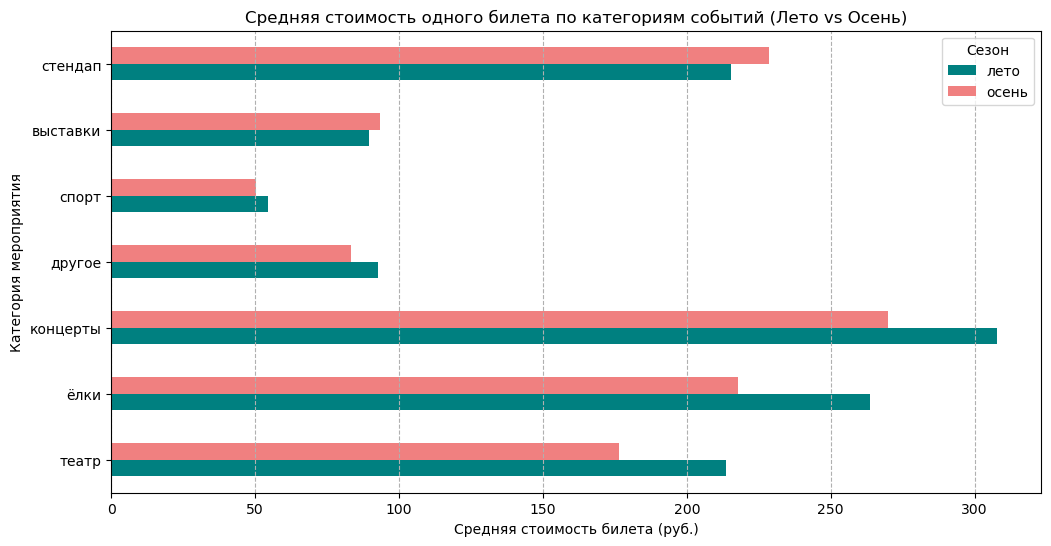


Изменение средней стоимости билета по категориям мероприятий:


season,лето,осень,изменение_руб,изменение_процент
event_type_main,,,,
стендап,215.18,228.67,13.49,6.27
выставки,89.47,93.47,4.00,4.47
спорт,54.65,50.21,-4.44,-8.12
другое,92.57,83.17,-9.39,-10.15
концерты,307.71,269.80,-37.91,-12.32
ёлки,263.50,217.89,-45.61,-17.31
театр,213.62,176.55,-37.08,-17.36


In [66]:
ticket_prices_table[['лето', 'осень']][::-1].plot(
    kind='barh',
    figsize=(12, 6),
    color=['teal', 'lightcoral'],
    title='Средняя стоимость одного билета по категориям событий (Лето vs Осень)'
)

# Настраиваем оформление графика:
plt.ylabel('Категория мероприятия')
plt.xlabel('Средняя стоимость билета (руб.)')
plt.xlim(0, None)
plt.legend(title='Сезон')
plt.grid(axis='x', linestyle='--')

# Выводим график:
plt.show()

# Выведем итоговую таблицу, отсортированную по изменению цены в процентах:
print("\nИзменение средней стоимости билета по категориям мероприятий:")
display(ticket_prices_table.round(2))


<br>**Вывод по результатам анализа средней стоимости билетов:**
<br>Сравнение средних чеков показало, что при переходе к осеннему сезону стоимость одного билета снизилась для большинства типов мероприятий:

* **Категории с ростом цены**: Незначительное подорожание билетов зафиксировано только в двух сегментах — `«стендап»` (рост на 13.49 руб. (**+6.27%**), составив 228.67 руб.) и `«выставки»` (рост на 4.00 руб. (**+4.47%**), увеличив цену до 93.47 руб.).
* **Категории со снижением цены**: Стоимость билетов немного снизилась в категориях `«спорт»` (на **8.12%**, с 54.65 до 50.21 руб.), `«другое»` (на **10.15%**, с 92.57 до 83.17 руб.) и `«концерты»` (на **12.32%**, с 307.71 до 269.80 руб.). Самый заметный спад среднего чека произошел в сегментах — `«ёлки»` (на **17.31%**, с 263.50 до 217.89 руб.) и `«театр»` (на **17.36%**, с 213.62 до 176.55 руб.).

Несмотря на то, что осенью общее количество заказов в этих категориях выросло, средняя стоимость одного проданного билета заметно снизилась. Это может быть связано с проведением акций, внедрением более доступных ценовых зон или изменением репертуара.

<br>

#### <a id="p3_1_4"></a> Общий вывод по распределению заказов по категориям и их сезонных изменений

Исследование показало, что с наступлением осени структура спроса меняется неравномерно: в то время как **выбор устройств и посещаемость выставок остаются абсолютно стабильными**, интерес к *спортивным, театральным и новогодним мероприятиям переживает резкий всплеск*. При этом общая активизация аудитории сопровождается **заметным снижением средней стоимости одного билета** в самых дорогих и массовых категориях. Такое падение среднего чека на фоне растущего числа заказов указывает на то, что осенний приток клиентов обеспечивается в первую очередь за счёт *более доступных ценовых сегментов или активных маркетинговых акций сервиса*.

*Важное примечание:* Полученные результаты наглядно показывают разницу в поведении пользователей летом и осенью, но пока их стоит рассматривать как сильные гипотезы. Поскольку мы анализируем данные всего за один изолированный год, на текущую динамику могли повлиять разовые факторы — например, крупные рекламные кампании или точечные акции. Уверенно говорить об устойчивой календарной сезонности можно будет только после сравнения аналогичных месяцев за несколько лет подряд.

<br>

### <a id="p3_2"></a> Осенняя активность пользователей

В данном разделе мы подробно изучим поведение пользователей в осенний период. Мы проанализируем ежедневную динамику заказов, посещаемость сервиса (DAU) и средний чек, а также исследуем недельную цикличность, чтобы определить и сравнить пользовательскую активность в будни и выходные дни.

#### <a id="p3_2_1"></a> Расчет ежедневных показателей и анализ динамики осенней активности

В этом подразделе мы выделим данные за осенний период и рассчитаем ключевые метрики активности по дням: `общее число заказов`, `количество уникальных пользователей (DAU)`, `среднее число заказов на одного клиента` и `среднюю стоимость одного билета`. На основе полученной таблицы мы построим линейные графики, с помощью созданной пользовательской функции, чтобы наглядно оценить ежедневную динамику пользовательского спроса.

<br>*Оставляем данные только за осенний период:*

In [67]:
autumn_df = tickets_df[tickets_df['season'] == 'осень'].reset_index()

<br>Для анализа **средней стоимости одного билета** согласно техническому заданию требуется показатель `чистой цены`. Однако в исходных данных поле `total` содержит общую стоимость всего заказа (*включая ситуации с покупкой нескольких билетов*) и представлено в двух разных валютах (*рубли и тенге*).

В качестве альтернативы в данных уже присутствует рассчитанное в рублях поле выручки за один билет (`one_ticket_revenue_rub`). Перед тем как строить графики динамики цен, проверим взаимосвязь этих двух показателей. Если цена билета и выручка сильно **коррелируют**, мы сможем использовать поле выручки как надежный аналог стоимости. 

**Для проверки рассчитаем коэффициент корреляции Пирсона** на сопоставимой рублевой выборке.

<br>*Фильтруем данные только для рублевых заказов из уже готового осеннего датафрейма:*

In [68]:
rub_autumn = autumn_df[autumn_df['currency_code'] == 'rub'].copy()

<br>*Считаем стоимость одного билета в заказе:*

In [69]:
rub_autumn['ticket_price'] = rub_autumn['total'] / rub_autumn['tickets_count']

<br>*Находим коэффициент корреляции между ценой и выручкой:*

In [70]:
corr_value = rub_autumn['ticket_price'].corr(rub_autumn['one_ticket_revenue_rub'])
print(f"Коэффициент корреляции Пирсона: {corr_value:.2f}")


Коэффициент корреляции Пирсона: 0.87


<br>Полученный коэффициент корреляции Пирсона ($r = 0.87$) свидетельствует о сильной линейной связи между расчетной стоимостью билета и выручкой: показатели изменяются синхронно, и динамика выручки будет с высокой точностью повторять тренды изменения реальных цен. 

Таким образом, мы обоснованно можем использовать `one_ticket_revenue_rub` в качестве полноценного аналога стоимости билета. Теперь перейдём к расчету ежедневных показателей для последующего построения графиков динамики.

<br>*Создаем сводную таблицу группируя осенние данные по дням (используем дату создания заказа) и считаем метрики через словарь {}:*

In [71]:
daily_activity = autumn_df.groupby('created_dt_msk').agg({
    'order_id': 'count',
    'user_id': 'nunique',
    'one_ticket_revenue_rub': 'mean'
})

<br>*Переименуем столбцы, чтобы таблица выглядела наглядно:*

In [72]:
daily_activity.columns = ['total_orders', 'dau', 'mean_ticket_price']

<br>*Добавляем расчет среднего числа заказов на одного активного пользователя и выведим первые 5 строк таблицы для проверки:*

In [73]:
daily_activity['orders_per_user'] = daily_activity['total_orders'] / daily_activity['dau']
display(daily_activity.head())

,total_orders,dau,mean_ticket_price,orders_per_user
created_dt_msk,,,,
2024-09-01,1314,555,202.149063,2.367568
2024-09-02,1369,571,190.969849,2.397548
2024-09-03,5090,776,80.713516,6.559278
2024-09-04,1757,683,179.598083,2.572474
2024-09-05,1936,738,190.156540,2.623306


<br>Поскольку далее нам предстоит построить и проанализировать четыре однотипных линейных графика для каждой из рассчитанных метрик, напишем универсальную функцию. Она будет принимать на вход имя столбца с метрикой и необходимые текстовые подписи, после чего строить аккуратный и единообразно оформленный линейный график динамики. Но для того чтобы графики ежедневной динамики метрик отображались корректно, а подписи на оси времени не перекрывали друг друга, переведем формат дат из системного типа в простой текстовый вид. Для удобства восприятия оставим в подписях только день и месяц.

<br>**Создадим функцию для построения линейных графиков динамики ежедневных показателей:**

In [74]:
def plot_daily_metric(column_name, title, ylabel):
    # Превращаем даты из индекса в обычный текст:
    daily_activity[column_name].index = daily_activity.index.strftime('%d.%m')
    
    # Строим линейный график для ежедневных метрик:
    daily_activity[column_name].plot(
        kind='line',
        figsize=(12, 6),
        color='mediumslateblue',
        marker='o',
        title=title
    )
    
    # Настраиваем оформление для графика:
    plt.xlabel('Дата заказа')
    plt.ylabel(ylabel)
    plt.grid(linestyle='--')
    
    # Выводим график:
    plt.show()


<br>

##### <a id="p3_2_1_1"></a> **3.2.1.1. Динамика общего количества заказов по дням**

В этом подразделе мы изучим, как менялось общее число оформленных заказов изо дня в день в течение осеннего периода. Линейный график поможет наглядно увидеть общую тенденцию спроса и обнаружить возможные всплески или спады активности.

<br>*С помощью функции `plot_daily_metric` построим линейный график для общего количества заказов:*

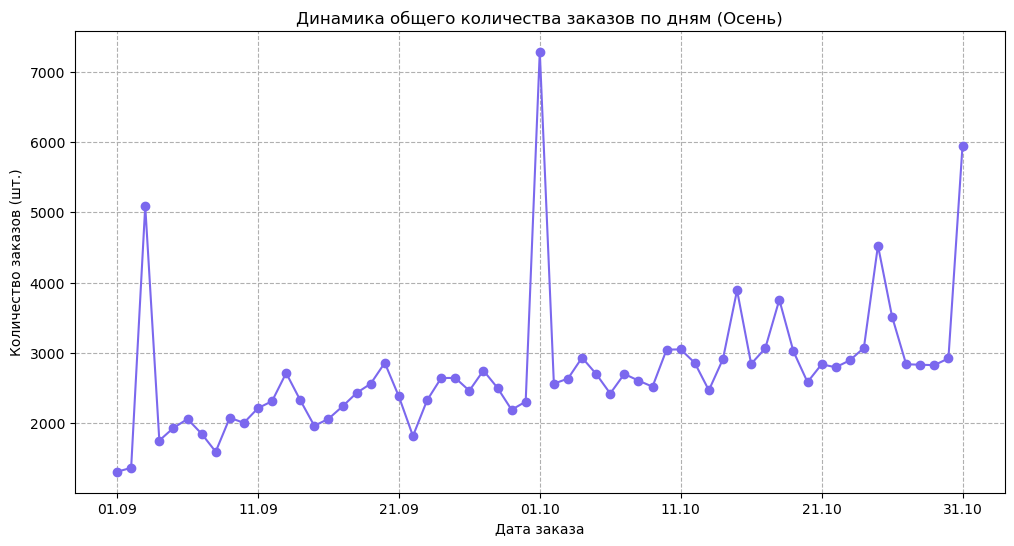

In [75]:
plot_daily_metric('total_orders', 'Динамика общего количества заказов по дням (Осень)', 'Количество заказов (шт.)')


<br>**Вывод по результатам анализа динамики общего количества заказов:**
<br>Ежедневная активность пользователей в осенний период характеризуется стабильным базовым спросом с тремя ярко выраженными пиками продаж:
* **Органический рост**: Минимальный уровень ежедневных заказов плавно и стабильно увеличивается на протяжении всего сезона. Если в начале сентября базовые показатели находились на уровне менее 2000 заказов в день, то к концу октября этот порог уверенно зафиксировался в районе 3000 заказов.
* **Резкие всплески активности**: На графике четко выделяются три мощных пика. Первый зафиксирован в самом начале сентября (около 5000 заказов), второй — на стыке месяцев, 1 октября (абсолютный максимум, превысивший 7000 заказов), и третий — в самом конце октября (около 6000 заказов).

Такое сочетание плавного роста и резких изолированных пиков указывает на то, что на фоне общего сезонного увеличения интереса к сервису происходили краткосрочные события — например, крупные маркетинговые акции или старты продаж билетов на долгожданные мероприятия.

<br>

##### <a id="p3_2_1_2"></a> **3.2.1.2. Динамика ежедневного количества уникальных пользователей (DAU)**

В этом подразделе мы проанализируем изменение посещаемости сервиса по дням на протяжении осени. Линейный график позволит отследить динамику уникальной аудитории и сопоставить её с общим количеством заказов.

<br>*С помощью функции `plot_daily_metric` построим линейный график для количества уникальных пользователей (DAU):*

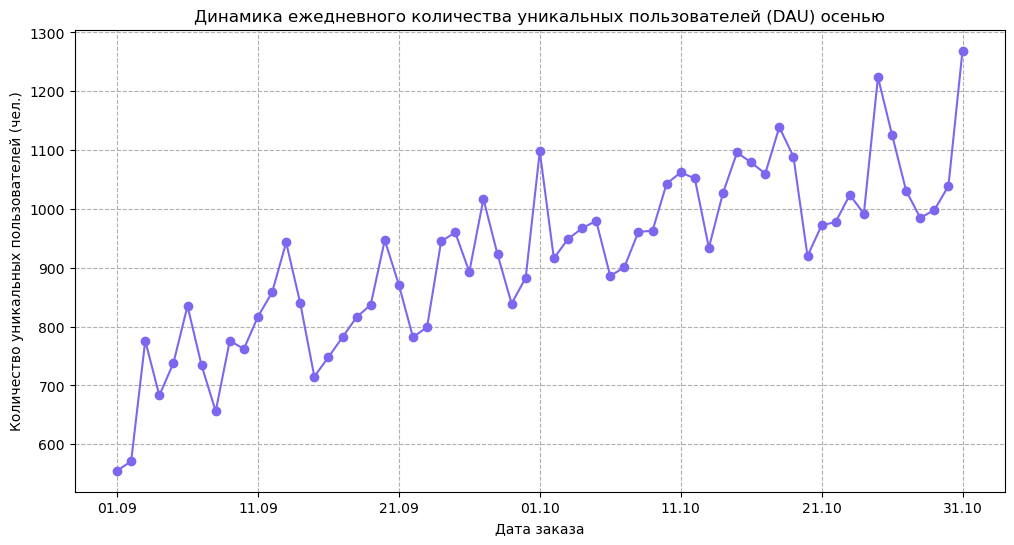

In [76]:
plot_daily_metric('dau', 'Динамика ежедневного количества уникальных пользователей (DAU) осенью', 'Количество уникальных пользователей (чел.)')


<br>**Вывод по результатам анализа динамики ежедневных уникальных пользователей (DAU):**
<br>Ежедневная посещаемость сервиса в осенний период демонстрирует стабильный органический рост с выраженной недельной цикличностью:
* **Органический рост аудитории**: График показывает уверенный восходящий тренд на протяжении всего сезона. Если в начале сентября ежедневное количество уникальных пользователей находилось на уровне менее 600 человек, то к концу октября этот показатель вырос более чем в два раза, достигнув пика более 1200 пользователей.
* **Недельная цикличность**: В отличие от графика заказов, где преобладали точечные всплески, посещаемость имеет четкую волнообразную структуру. Переодически повторяются регулярные спады и подъемы, что говорит о сильной зависимости визитов от дней недели.

Постоянный рост графика подтверждает, что сервис успешно привлекает и удерживает новых клиентов, формируя стабильное ядро активной аудитории к концу октября.

<br>

##### <a id="p3_2_1_3"></a> **3.2.1.3. Динамика среднего количества заказов на одного пользователя**

В этом подразделе мы исследуем, как в течение осени менялось среднее число заказов, приходящееся на одного активного клиента в день. Это поможет понять, возрастает ли плотность покупок со стороны пользователей при приближении к концу сезона.

<br>*С помощью функции `plot_daily_metric` построим линейный график для среднего количества заказов на пользователя:*

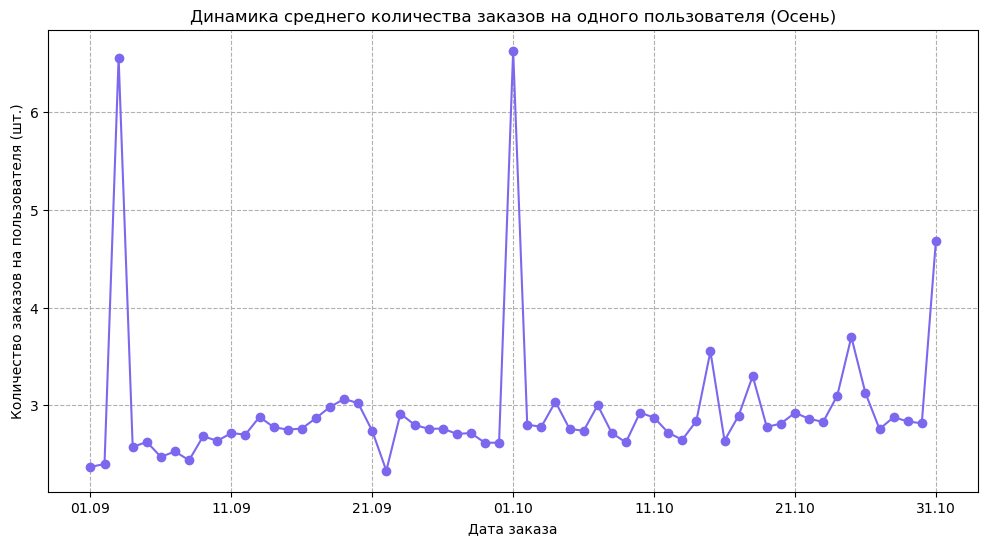

In [77]:
plot_daily_metric('orders_per_user', 'Динамика среднего количества заказов на одного пользователя (Осень)', 'Количество заказов на пользователя (шт.)')


<br>**Вывод по результатам анализа динамики среднего количества заказов на одного пользователя:**
<br>Анализ плотности покупок демонстрирует стабильное ежедневное поведение клиентов с резкими всплесками активности, которые идеально дублируют график общего количества заказов:
* **Базовый уровень активности**: В обычные осенние дни среднее число заказов на одного активного пользователя практически неизменно и удерживается в узком коридоре около 2.5–3.0 заказов в день. 
* **Аномальные скачки плотности**: На графике отчётливо выделяются два мощных вертикальных пика. Первый зафиксирован в самом начале сентября, а второй — 1 октября. В эти даты показатель резко удваивается и превышает отметку в 6 заказов на одного человека.

Такое стопроцентное совпадение с графиком общего количества заказов говорит об одном: в дни аномалий общий рост продаж произошёл не просто за счёт притока новых уникальных посетителей на сайт, а именно из-за резкого изменения поведения существующих клиентов. В эти конкретные дни пользователи массово оформляли по несколько заказов подряд в одни руки.

<br>

##### <a id="p3_2_1_4"></a> **3.2.1.4. Динамика средней стоимости одного билета**

В этом подразделе мы изучим, как изо дня в день в течение осени менялась средняя стоимость одного билета в заказах. Линейный график позволит отследить колебания цен на мероприятия и выявить дни с аномально высокой или низкой стоимостью покупок.

<br>*С помощью функции `plot_daily_metric` построим линейный график для средней стоимости одного билета:*

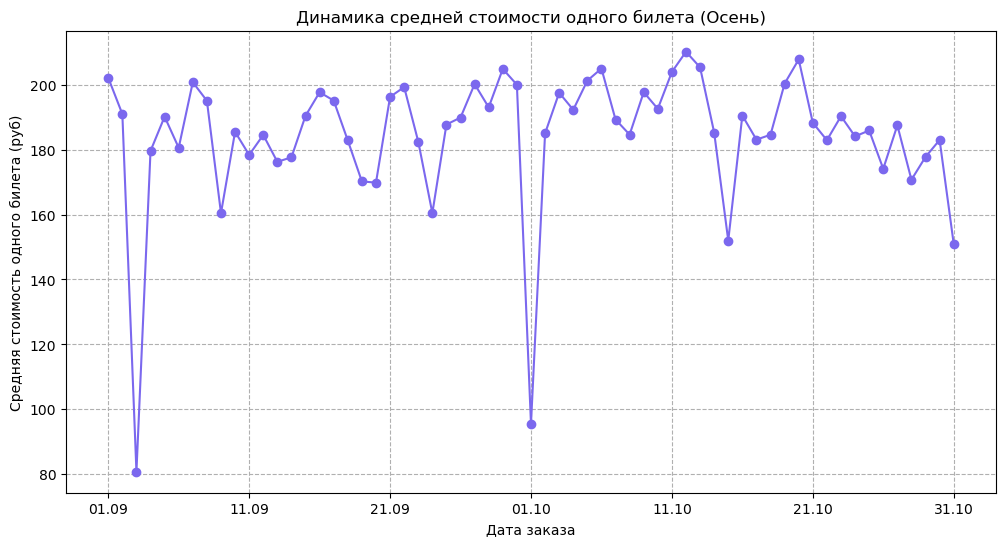

In [78]:
plot_daily_metric('mean_ticket_price', 'Динамика средней стоимости одного билета (Осень)', 'Средняя стоимость одного билета (руб)')


<br>**Вывод по результатам анализа динамики средней стоимости билетов:**
<br>Ежедневная средняя стоимость одного билета в осенний период демонстрирует стабильное поведение с двумя критическими спадами, которые полностью объясняют прирост продаж:
* **Базовый уровень цен**: На протяжении большей части осени средняя цена одного билета колеблется в достаточно узком диапазоне — примерно от 180 до 200 рублей.
* **Аномальные провалы стоимости**: На графике чётко видны два глубоких спада, когда средняя цена билета резко падала. В самом начале сентября зафиксирован абсолютный минимум (около 80 рублей), а на стыке месяцев, 1 октября, цена опустилась чуть ниже 100 рублей.

Эти даты со стопроцентной точностью совпадают с аномальными пиками из графиков общего количества заказов и плотности покупок на одного пользователя. Это полностью подтверждает догадки, что резкие скачки продаж в эти дни были вызваны именно масштабными скидочными акциями, распродажами или раздачей дешевых промокодов, которые временно обрушили средний чек, но привлекли огромный поток покупателей и заставили клиентов брать по несколько билетов в одни руки.

<br>

#### <a id="p3_2_2"></a> Анализ недельной цикличности активности пользователей

В этом подразделе мы исследуем, как распределяются средние ежедневные показатели для каждого дня недели в осенний период. Это позволит выявить скрытые закономерности пользовательского поведения, определить пиковые дни активности в будни и выходные, а также найти периоды естественного спада продаж.

Для получения объективной картины распределения активности важно учитывать, что осенний период содержит неодинаковое количество конкретных дней недели (например, число вторников или суббот в календаре может различаться). Поэтому для корректного анализа мы сначала определим день недели для каждой даты, а затем будем считать **СРЕДНЕЕ** для `общего число заказов`, `количества уникальных пользователей (DAU)`, `среднего число заказов на одного клиента` и `средней стоимость одного билета`.

<br>*Извлекаем день недели из дат суточной активности пользователей:*

In [79]:
daily_activity['day_of_week'] = daily_activity.index.day_name()

<br>*Группируем по дням недели и считаем **СРЕДНЕЕ** по метрикам активности пользователей:*

In [80]:
weekday_activity = daily_activity.groupby('day_of_week')[['total_orders', 'dau', 'orders_per_user', 'mean_ticket_price']].mean()

<br>*Указываем правильный хронологический порядок, чтобы график шёл от понедельника до воскресенья:*

In [81]:
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_activity = weekday_activity.reindex(days_order)

<br>*Переименуем индексы на русский язык для привычного отображения на графике*

In [82]:
ru_days = ['Понедельник', 'Вторник', 'Среда', 'Четверг', 'Пятница', 'Суббота', 'Воскресенье']
weekday_activity.index = ru_days

<br>***Создадим пользовательскую функцию**, которая построим горизонтальную столбчатую диаграмму для каждой из метрик по дням недели и выведет значения по каждому показателю:*

In [83]:
def plot_weekday_metric(column_name, title, xlabel):
    # Строим горизонтальный график для конкретной метрики:
    weekday_activity[column_name][::-1].plot(
        kind='barh',
        figsize=(12, 6),
        color='lightcoral',
        title=title
    )
    
    # Настраиваем оформление для графика:
    plt.ylabel('День недели')
    plt.xlabel(xlabel)
    plt.xlim(0, None)
    plt.grid(axis='x', linestyle='--')

    # Выводим график:
    plt.show()

    # Выведем таблицу со значениями для конкретной метрики:
    print(f"\nЗначение показателя: {xlabel}")
    display(weekday_activity[[column_name]].style.format('{:.2f}'))


<br>*С помощью функции `plot_weekday_metric` построим график для среднего количества заказов за один день недели:*

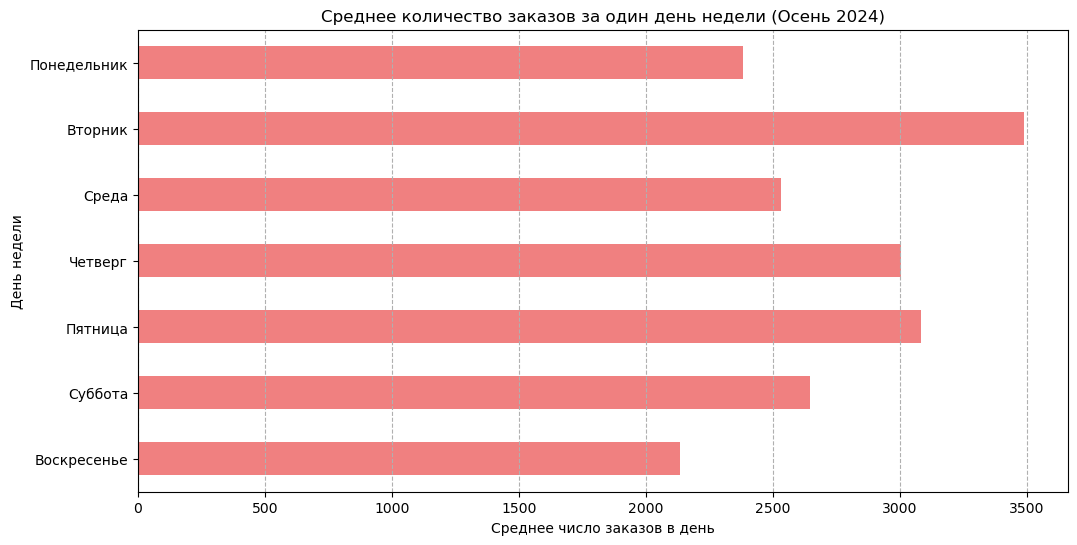


Значение показателя: Среднее число заказов в день


,total_orders
Понедельник,2382.78
Вторник,3488.11
Среда,2534.11
Четверг,3005.22
Пятница,3082.88
Суббота,2647.38
Воскресенье,2135.22


In [84]:
plot_weekday_metric('total_orders', 'Среднее количество заказов за один день недели (Осень 2024)', 'Среднее число заказов в день')


<br>*С помощью функции `plot_weekday_metric` построим график для среднего количества уникальных пользователей в день:*

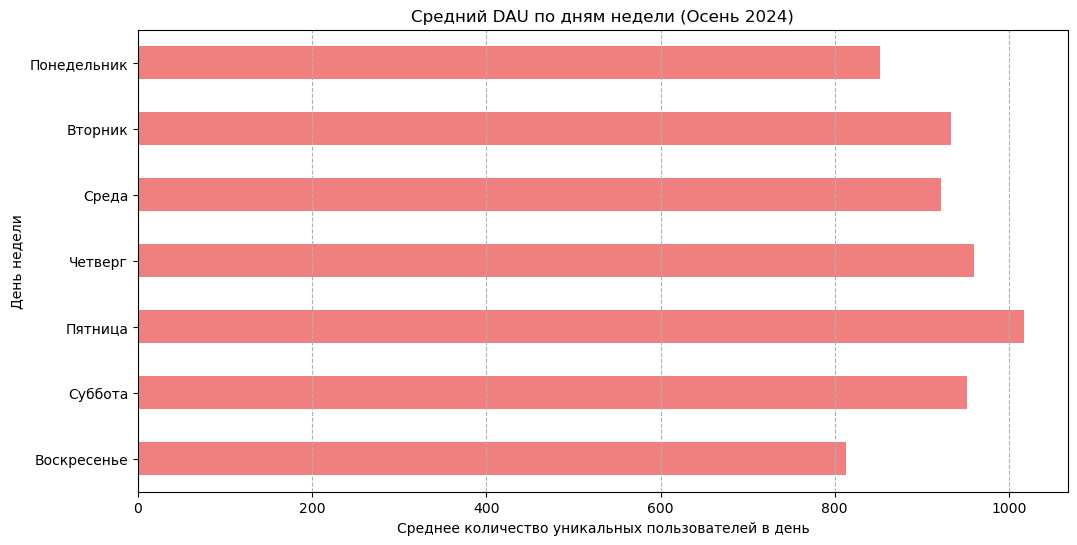


Значение показателя: Среднее количество уникальных пользователей в день


,dau
Понедельник,851.33
Вторник,932.89
Среда,921.89
Четверг,959.89
Пятница,1016.75
Суббота,951.88
Воскресенье,813.11


In [85]:
plot_weekday_metric('dau', 'Средний DAU по дням недели (Осень 2024)', 'Среднее количество уникальных пользователей в день')


<br>*С помощью функции `plot_weekday_metric` построим график для среднего количества заказов на одного пользователя по дням недели:*

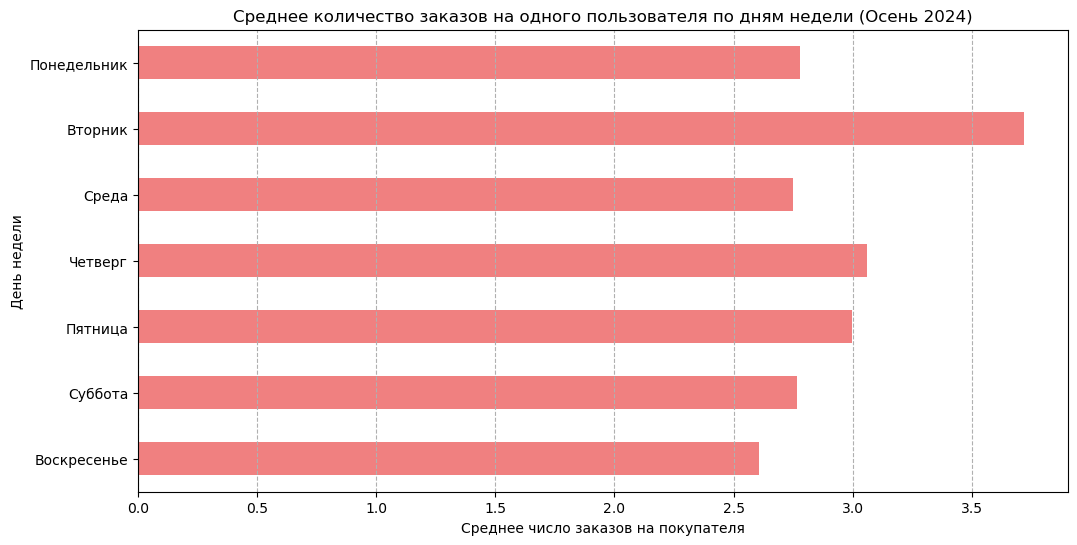


Значение показателя: Среднее число заказов на покупателя


,orders_per_user
Понедельник,2.78
Вторник,3.72
Среда,2.75
Четверг,3.06
Пятница,3.00
Суббота,2.77
Воскресенье,2.61


In [86]:
plot_weekday_metric('orders_per_user', 'Среднее количество заказов на одного пользователя по дням недели (Осень 2024)', 'Среднее число заказов на покупателя')


<br>*С помощью функции `plot_weekday_metric` построим график для средней стоимости билета в рублях по дням недели:*

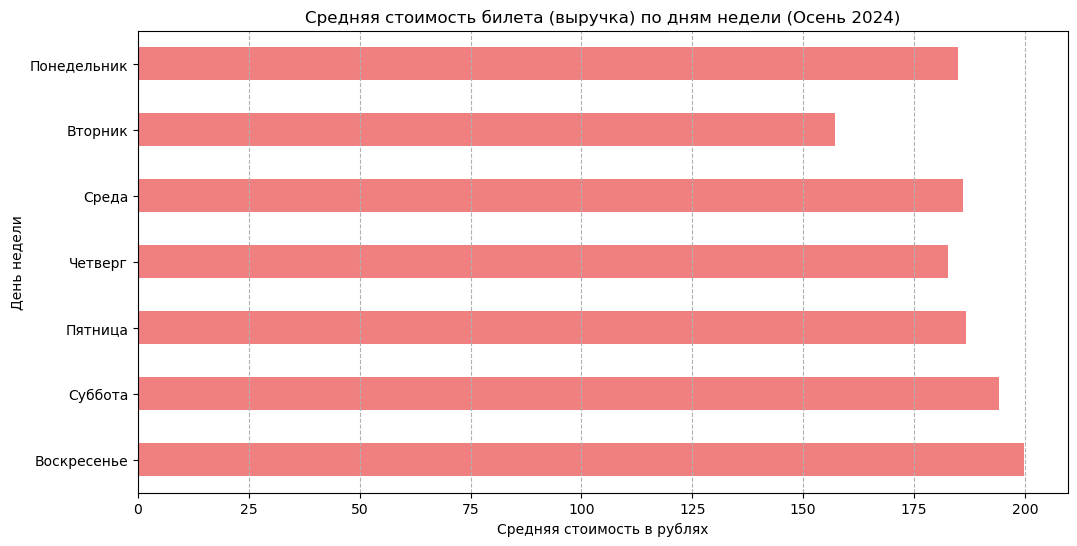


Значение показателя: Средняя стоимость в рублях


,mean_ticket_price
Понедельник,185.01
Вторник,157.16
Среда,186.11
Четверг,182.56
Пятница,186.69
Суббота,194.20
Воскресенье,199.72


In [87]:
plot_weekday_metric('mean_ticket_price', 'Средняя стоимость билета (выручка) по дням недели (Осень 2024)', 'Средняя стоимость в рублях')


<br>**Выводы по анализу недельной активности пользователей**
<br>Исследование средних ежедневных показателей по дням недели позволило выявить ключевые особенности распределения активности пользователей внутри недели:
* **Пик активности во вторник:** Вторник является абсолютным лидером по количеству оформленных заказов (в среднем **3488.11** в день). Данный всплеск обусловлен исключительно высокой плотностью заказов на одного активного пользователя — этот показатель достигает **3.72**. При этом средний DAU во вторник остается на стандартном уровне (**932.89**), а средняя стоимость билета падает до минимального недельного значения — **157.16 руб.**
* **Стабильный органический спрос:** Вторая половина недели демонстрирует плавный рост посещаемости платформы с максимумом в пятницу (средний DAU — **1016.75**). Пользователи активно заходят в приложение перед выходными, совершая в среднем около 3 заказов.
* **Спад в выходные дни:** В субботу и воскресенье фиксируется снижение посещаемости и общего числа заказов (минимум в воскресенье — **813.11** и **2135.22** соответственно). При этом средняя стоимость билета в конце недели достигает максимальных значений (**194.20 руб.** в субботу и **199.72 руб.** в воскресенье), что указывает на преобладание вынужденных или срочных покупок по полной цене.

<br>

#### <a id="p3_2_3"></a> Общий вывод по анализу осенней активности

В ходе комплексного исследования активности пользователей за осенний период были изучены ключевые продуктовые метрики (общее число заказов, DAU, среднее число заказов на пользователя и средняя стоимость билета) в разрезе ежедневной динамики и дней недели.

**Основные результаты исследования:**
* На протяжении всей осени ключевые метрики демонстрируют стабильное поведение с выраженной еженедельной цикличностью: пик активности приходится на будние дни, а спад — на выходные. При этом в выходные дни пользователи совершают органические покупки с максимальным средним чеком (около 195–200 руб.).
* Обнаружены изолированные аномальные пики активности, которые стабильно повторяются в начале каждого месяца (1 сентября, 1 октября), а также еженедельно по вторникам. В эти дни количество заказов и плотность покупок на одного пользователя резко возрастают, в то время как средняя стоимость билета падает до минимума.

<br>**Рекомендации и направления для дальнейшего анализа:**
Для более глубокого понимания бизнес-показателей и оптимизации платформы целесообразно провести дополнительное дорасследование по следующим направлениям:
* **Анализ регулярности маркетинговых кампаний:** Выявленные цикличные пики со снижением среднего чека с высокой вероятностью указывают на проведение ежемесячных и еженедельных (по вторникам) плановых распродаж или акций. Необходимо сопоставить эти даты с маркетинговым календарем, чтобы оценить реальный экономический эффект от таких мероприятий и определить, на какие именно категории билетов распространялись скидки.
* **Исследование аномального пласта пользователей:** Высокая плотность заказов во вторник (почти 4 покупки на одного покупателя) может свидетельствовать об активности автоматизированных ботов или профессиональных перекупщиков, массово скупающих билеты по акционным ценам. В качестве следующего шага аналитики рекомендуется провести эксперимент: объединить заказы каждого пользователя за день в единые сеансы и пересчитать метрики без учета этой плотности. Это позволит очистить данные от «шума» перекупов и увидеть чистую динамику реальных розничных клиентов.

<br>

### <a id="p3_3"></a> Популярные события и партнёры

В этом разделе мы исследуем, как мероприятия и продажи распределены по географическим регионам и билетным операторам. Это позволит определить ключевые рынки с наибольшим разнообразием репертуара, а также выявить самых активных партнёров, которые вносят наибольший вклад в общую выручку сервиса.

#### <a id="p3_3_1"></a> Анализ распределения мероприятий и заказов по регионам

В данном подразделе мы определим количество уникальных событий и общий объём заказов для каждого региона. Чтобы оценить масштаб каждого рынка, мы также рассчитаем их доли в процентах от общих показателей сервиса и выделим ТОП — 7 лидеров с самым разнообразным репертуаром. А так же построим график, чтоб наглядно веделить более разнообразные регионы.

<br>*Сгруппируем данные по регионам и посчитаем уникальные мероприятия и заказы:*

In [88]:
region_summary = tickets_df.groupby('region_name', observed=False).agg({
    'event_id': 'nunique', 
    'order_id': 'count'
})

<br>*Переименуем столбцы для понятности:*

In [89]:
region_summary.columns = ['Уникальные_события', 'Всего_заказов']

<br>*Считаем доли в процентах от общих показателей по всей Афише:*

In [90]:
total_events = tickets_df['event_id'].nunique()
total_orders = len(tickets_df)

region_summary['Доля_событий_%'] = (region_summary['Уникальные_события'] / total_events) * 100
region_summary['Доля_заказов_%'] = (region_summary['Всего_заказов'] / total_orders) * 100

<br>*Сортируем таблицу по убыванию разнообразия мероприятий и берём ТОП-7 регионов:*

In [91]:
top_regions = region_summary.sort_values(by='Уникальные_события', ascending=False).head(7)

<br>*Строим сгруппированную горизонтальную столбцатую диаграмму для сравнения долей событий и заказов:*

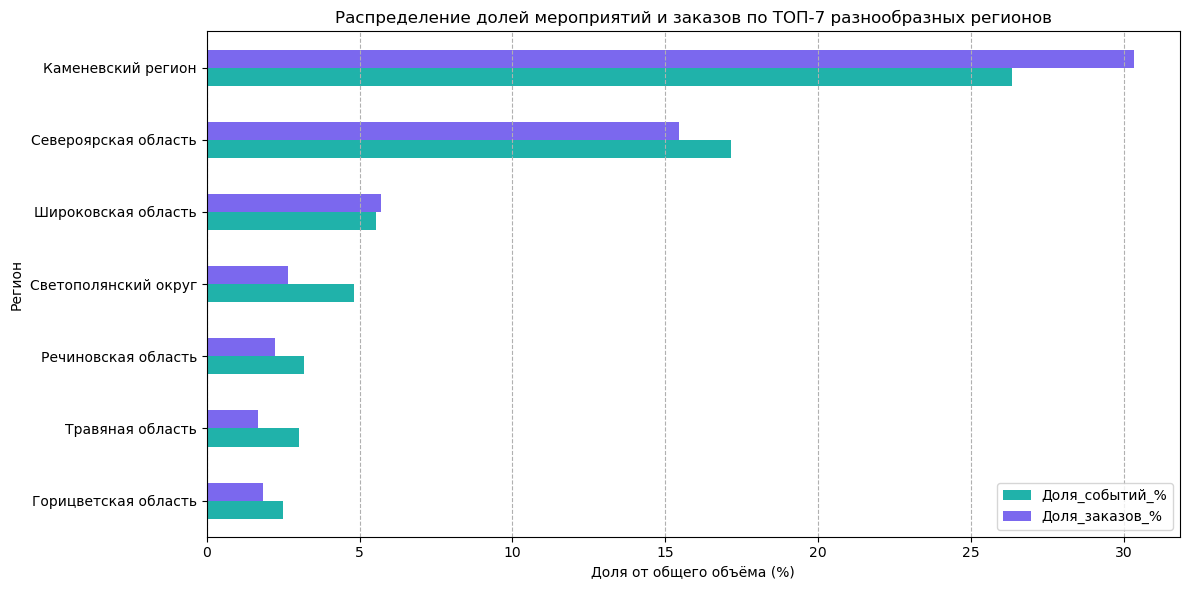


ТОП-7 регионов по разнообразию мероприятий и объёму заказов:


,Уникальные_события,Всего_заказов,Доля_событий_%,Доля_заказов_%
region_name,,,,
Каменевский регион,5792,85357,26.33,30.31
Североярская область,3774,43462,17.15,15.43
Широковская область,1217,16080,5.53,5.71
Светополянский округ,1059,7458,4.81,2.65
Речиновская область,701,6261,3.19,2.22
Травяная область,667,4719,3.03,1.68
Горицветская область,551,5152,2.50,1.83


In [92]:
top_regions[['Доля_событий_%', 'Доля_заказов_%']][::-1].plot(
    kind='barh',
    figsize=(12, 6),
    color=['lightseagreen', 'mediumslateblue'],
    title='Распределение долей мероприятий и заказов по ТОП-7 разнообразных регионов'
)

# Настраиваем оформление графика
plt.xlabel('Доля от общего объёма (%)')
plt.ylabel('Регион')
plt.grid(axis='x', linestyle='--')
plt.tight_layout()
plt.show()

# Вывдем итоговую таблицу:
print("\nТОП-7 регионов по разнообразию мероприятий и объёму заказов:")
display(top_regions.round(2))


<br>**Вывод по результатам анализа распределения по регионам:**
<br>Анализ географического распределения выявил ключевые особенности территориального развития платформы:
* **Абсолютные лидеры (Высокая концентрация рынка):** Основными рынками для сервиса выступают два региона — **Каменевский регион** (26.33% уникальных событий и 30.31% всех заказов) и **Североярская область** (17.15% событий и 15.43% заказов). Суммарно на эти два региона приходится почти половина всего репертуара и продаж платформы, что указывает на сильную зависимость бизнеса от этих двух локаций.
* **Региональный дисбаланс спроса:** В Каменевском регионе доля заказов заметно превышает долю доступных мероприятий, что говорит о высокой активности местной аудитории. В Североярской области, напротив, доля событий выше доли продаж, что указывает на потенциал для дальнейшего роста эффективности этого рынка.
* **Остальные регионы ТОП-7:** Все последующие регионы в списке существенно уступают лидерам. Доля каждого из них не превышает 5.6% по событиям и 5.8% по объёму заказов. Это подтверждает, что за пределами двух главных регионов деятельность компании развита слабо, а локальные рынки находятся на начальном этапе формирования.

<br>

#### <a id="p3_3_2"></a> Анализ распределения заказов и выручки по билетным операторам

В этом подразделе мы исследуем показатели работы билетных партнеров (операторов) сервиса. Мы рассчитаем общее число уникальных мероприятий, количество оформленных заказов и суммарную выручку для каждого оператора, а также определим их процентные доли, чтобы выявить ключевых игроков, приносящих платформе основной доход. И визуально отобразим ТОП — 7 наиболее активных партнёров.

<br>*Группируем данные по операторам и считаем уникальные события, заказы и общую выручку:*

In [93]:
service_summary = tickets_df.groupby('service_name', observed=False).agg({
    'event_id': 'nunique',
    'order_id': 'count',
    'revenue_rub': 'sum'
})

<br>*Переименуем столбцы для наглядности:*

In [94]:
service_summary.columns = ['Уникальные_события', 'Всего_заказов', 'Общая_выручка_руб']

<br>*Считаем доли в процентах от общих показателей всей платформы:*

In [95]:
total_events = tickets_df['event_id'].nunique()
total_orders = len(tickets_df)
total_revenue = tickets_df['revenue_rub'].sum()

service_summary['Доля_событий_%'] = (service_summary['Уникальные_события'] / total_events) * 100
service_summary['Доля_заказов_%'] = (service_summary['Всего_заказов'] / total_orders) * 100
service_summary['Доля_выручки_%'] = (service_summary['Общая_выручка_руб'] / total_revenue) * 100

<br>*Сортируем таблицу по убыванию количества заказов (активности) и берем ТОП-7:*

In [96]:
top_services = service_summary.sort_values(by='Всего_заказов', ascending=False).head(7)

<br>*Строим сгруппированную горизонтальную столбцатую диаграмму для сравнения долей событий, заказов и выручки:*

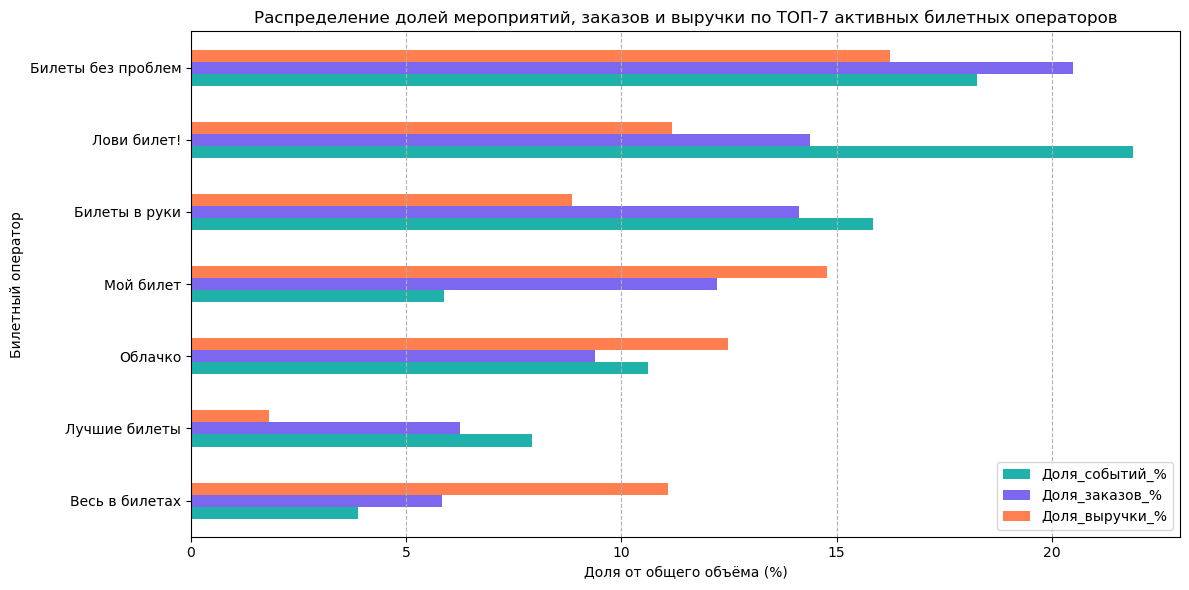


ТОП-7 активных билетных операторов по количеству заказов, по выручке и разнообразию мероприятий:


,Уникальные_события,Всего_заказов,Общая_выручка_руб,Доля_событий_%,Доля_заказов_%,Доля_выручки_%
service_name,,,,,,
Билеты без проблем,4015,57713,24189640.0,18.25,20.50,16.23
Лови билет!,4813,40488,16669880.0,21.88,14.38,11.18
Билеты в руки,3486,39779,13189521.0,15.85,14.13,8.85
Мой билет,1293,34393,22010142.0,5.88,12.21,14.77
Облачко,2335,26400,18586074.0,10.61,9.38,12.47
Лучшие билеты,1741,17604,2720507.0,7.91,6.25,1.83
Весь в билетах,855,16421,16529894.0,3.89,5.83,11.09


In [97]:
top_services[['Доля_событий_%', 'Доля_заказов_%', 'Доля_выручки_%']][::-1].plot(
    kind='barh',
    figsize=(12, 6),
    color=['lightseagreen', 'mediumslateblue', 'coral'],
    title='Распределение долей мероприятий, заказов и выручки по ТОП-7 активных билетных операторов'
)

# Настраиваем оформление графика
plt.xlabel('Доля от общего объёма (%)')
plt.ylabel('Билетный оператор')
plt.grid(axis='x', linestyle='--')
plt.tight_layout()
plt.show()

# Вывдем итоговую таблицу:
print("\nТОП-7 активных билетных операторов по количеству заказов, по выручке и разнообразию мероприятий:")
display(top_services.round(2))


<br>**Вывод по результатам анализа билетных операторов:**
<br>Анализ деятельности партнёров показал относительно равномерное распределение рынка с выделением ряда ключевых игроков:
* **Абсолютный лидер рынка:** Оператор `«Билеты без проблем»` занимает первое место по активности. На него приходится **20.50%** всех заказов платформы (57 713 штук). При этом компания лидирует и по финансовым показателям, генерируя **16.23%** от общей выручки сервиса. Это ключевой и самый стабильный партнер «Яндекс Афиши».
* **Лидер по разнообразию контента:** Оператор `«Лови билет!»` находится на втором месте по заказам (**14.38%**), но является абсолютным лидером по ассортименту. Через него проходит **21.88%** всех уникальных мероприятий платформы (4 813 событий). Это важнейший партнер с точки зрения привлечения разнообразного репертуара, хотя из-за невысокой стоимости его билетов доля в выручке отстаёт от объёма продаж и составляет **11.18%**.
* **Эффективный «второй эшелон»:** Операторы `«Мой билет»` и `«Облачко»`, находясь за пределами тройки лидеров по количеству заказов, демонстрируют высокую доходность. «Мой билет» генерирует **14.77%** всей выручки при доле заказов 12.21%, а «Облачко» — **12.47%** выручки при 9.38% заказов. Это указывает на высокий средний чек и премиальный сегмент билетов у данных операторов.
* **Скрытый потенциал на периферии рейтинга:** Замыкающий ТОП-7 оператор **`«Весь в билетах»`** при минимальной доле заказов (всего 5.83%) приносит платформе **11.09%** выручки. Данный партнёр имеет колоссальный потенциал для дальнейшего развития сотрудничества, так как каждая его продажа приносит компании высокую прибыль.

<br>

#### <a id="p3_3_3"></a> Общий промежуточный вывод по распределению данных между категориями

В этом пункте мы посчитаем общую структуру рынка «Яндекс Афиши», чтобы проверить наличие лидеров на цифрах. Мы узнаем точное количество регионов и билетных операторов в базе данных, а затем определим суммарный процент заказов, событий и выручки, который удерживают наши ТОП-7 категорий. Это покажет реальный уровень концентрации бизнеса на платформе.

<br>*Рассчитаем общую концентрацию рынка вокруг ТОП-7 регионов относительно всей платформы:*

In [98]:
# Считаем общую сумму долей, которую забирает ТОП-7 регионов
total_top_events_share = top_regions['Доля_событий_%'].sum()
total_top_orders_share = top_regions['Доля_заказов_%'].sum()
total_regions_count = region_summary.shape[0] # Общее число регионов до фильтрации .head(7)

print(f"Общее количество регионов в датасете: {total_regions_count}")
print(f"Доля уникальных событий, приходящаяся на ТОП-7 регионов: {total_top_events_share:.2f}%")
print(f"Доля всех заказов, приходящаяся на ТОП-7 регионов: {total_top_orders_share:.2f}%")


Общее количество регионов в датасете: 81
Доля уникальных событий, приходящаяся на ТОП-7 регионов: 62.55%
Доля всех заказов, приходящаяся на ТОП-7 регионов: 59.83%


<br>*Рассчитаем степень монополизации рынка билетных операторов вокруг ТОП-7 компаний:*

In [99]:
# Считаем общую сумму долей, которую забирает ТОП-7 операторов
total_top_services_events = top_services['Доля_событий_%'].sum()
total_top_services_orders = top_services['Доля_заказов_%'].sum()
total_top_services_revenue = top_services['Доля_выручки_%'].sum()
total_services_count = service_summary.shape[0] # Общее число операторов до фильтрации .head(7)

print(f"Общее количество билетных операторов в датасете: {total_services_count}")
print(f"Доля событий, приходящаяся на ТОП-7 операторов: {total_top_services_events:.2f}%")
print(f"Доля заказов, приходящаяся на ТОП-7 операторов: {total_top_services_orders:.2f}%")
print(f"Доля выручки, приходящаяся на ТОП-7 операторов: {total_top_services_revenue:.2f}%")


Общее количество билетных операторов в датасете: 36
Доля событий, приходящаяся на ТОП-7 операторов: 84.26%
Доля заказов, приходящаяся на ТОП-7 операторов: 82.67%
Доля выручки, приходящаяся на ТОП-7 операторов: 76.41%


<br>**Итоговый вывод по ключевым регионам и партнёрам:**

* **Распределение по регионам:** На платформе представлен **81 регион**, при этом `ТОП-7` забирают на себя **59.83%** всех заказов и **62.55%** уникальных событий. Рынок имеет высокую степень централизации. Основные риски бизнеса связаны с тем, что почти половину всех показателей удерживают всего два лидера (Каменевский регион и Североярская область), в то время как остальные регионы из семёрки сильно отстают и развиты слабо.
* **Распределение по операторам:** Всего в датасете **36 партнёров**, но `ТОП-7` из них практически полностью контролируют платформу. Они обеспечивают **84.26%** репертуара, забирают **82.67%** всех заказов и приносят **76.41%** общей выручки. Сервис критически зависит от работы этих семи компаний.

На платформе есть явные монополисты. `Среди регионов` — это **Каменевский регион** по объёму спроса. `Среди партнёров` — оператор **«Билеты без проблем»** (абсолютный лидер по заказам и деньгам) и **«Лови билет!»** (лидер по разнообразию мероприятий). 
<br>Такая высокая концентрация вокруг единичных лидеров создаёт стратегические **риски для платформы**. Для оптимизации бизнес-модели в будущем было бы полезно провести кросс-анализ на стыке этих данных: проверить, как распределяется конкуренция между операторами внутри каждого крупного региона и не захватил ли один партнёр полную монополию на местном рынке.

<br>

## <a id="p4"></a> Статистический анализ данных (Проверка гипотез)

В данном разделе мы проверим два предположения продуктовой команды о том, что пользователи мобильных устройств более вовлечены в сервис, чем пользователи стационарных компьютеров (десктопов). Нам предстоит проверить две продуктовые гипотезы:
1. Количество заказов на одного пользователя в мобильном приложении выше, чем на стационарных устройствах.
2. Время между заказами у пользователей мобильных приложений выше (интервал больше), чем у пользователей стационарных устройств.

Для анализа мы будем использовать исключительно очищенные данные за **осенний период** (`autumn_df`). Чтобы выводы были методологически верными, по каждому вопросу мы сначала исследуем структуру данных, выявим возможные взаимосвязи, подберем адекватный статистический критерий и только затем сформулируем и проверим гипотезы.

<br>

### <a id="p4_1"></a> Сравнение количества заказов на одного пользователя

В данном подразделе мы проверим первое предположение продуктовой команды: действительно ли пользователи в мобильном приложении за осень успевают сделать больше заказов, чем с десктопных устройств. 

Для этого мы сначала исследуем структуру данных и подберем корректный математический инструмент с учетом особенностей выборки, а затем сформулируем статистические гипотезы и проведем сам тест.

<br>

#### <a id="p4_1_1"></a>  Исследование структуры данных, визуализация распределений и выбор критерия

Перед тем как запускать статистический тест, нам нужно понять, как именно устроены наши выборки. Главное условие для классических тестов — это независимость данных. Это значит, что действия одного человека в одной выборке не должны влиять на данные в другой.

Однако в нашем интернет-магазине один и тот же клиент может делать заказы и с телефона, и с компьютера. У каждого покупателя своя индивидуальная активность и лояльность к сервису. Если мы просто разделим все заказы на две кучи по устройствам, в обе группы попадут одни и те же люди. Их поведение на ПК и в телефоне будет взаимосвязано, а это нарушит чистоту эксперимента.

Чтобы решить эту проблему и сделать выводы точными, мы объединим данные по каждому пользователю. Для каждого покупателя мы посчитаем две метрики: сколько раз он купил с мобильного и сколько раз с десктопа. Так мы перейдем к анализу связанных (парных) выборок.

<br>*Разделяем осенние данные на две независимые группы по типу устройства:*

In [100]:
mobile_autumn = autumn_df[autumn_df['device_type_canonical'] == 'mobile']
desktop_autumn = autumn_df[autumn_df['device_type_canonical'] == 'desktop']

<br>*Считаем количество уникальных заказов на каждого пользователя:*

In [101]:
mobile_user_orders = mobile_autumn.groupby('user_id')['order_id'].count().reset_index(name='mobile_user_orders')
desktop_user_orders = desktop_autumn.groupby('user_id')['order_id'].count().reset_index(name='desktop_user_orders')

<br>*Объединяем полученные данные по пользователю и заполняем нулями пропуски:*

In [102]:
user_orders_autumn = mobile_user_orders.merge(desktop_user_orders, on='user_id', how='outer').fillna(0)

<br>*Приводим количество заказов к целочисленному типу после заполнения пропусков:*

In [103]:
user_orders_autumn[['mobile_user_orders', 'desktop_user_orders']] = user_orders_autumn[['mobile_user_orders', 'desktop_user_orders']].astype(int)

<br>*Выводим первые 10 строк для проверки результата:*

In [104]:
display(user_orders_autumn.head(10))

,user_id,mobile_user_orders,desktop_user_orders
0,0005ca5e93f2cf4,1,0
1,000898990054619,2,0
2,000a55a418c128c,2,0
3,001e7037d013f0f,2,0
4,00245c702bc343e,2,0
5,0028d17a676f8c8,1,1
6,002b75ca606ba46,1,3
7,002ec276eee9b0b,11,1
8,0033403583a55ed,1,0
9,0033e08fba8d0c9,1,0


<br>

**Визуализация распределения количества заказов**

Используем ранее созданную функцию `plot_hist_and_box` для детального анализа числового распределения количества заказов отдельно для мобильного приложения и десктопной версии сайта. Это позволит нам наглядно сравнить форму распределений, оценить смещение данных и увидеть основные описательные статистики.


<br>*Строим совмещенные графики для **мобильных** и для **десктопных** заказов за осень:*

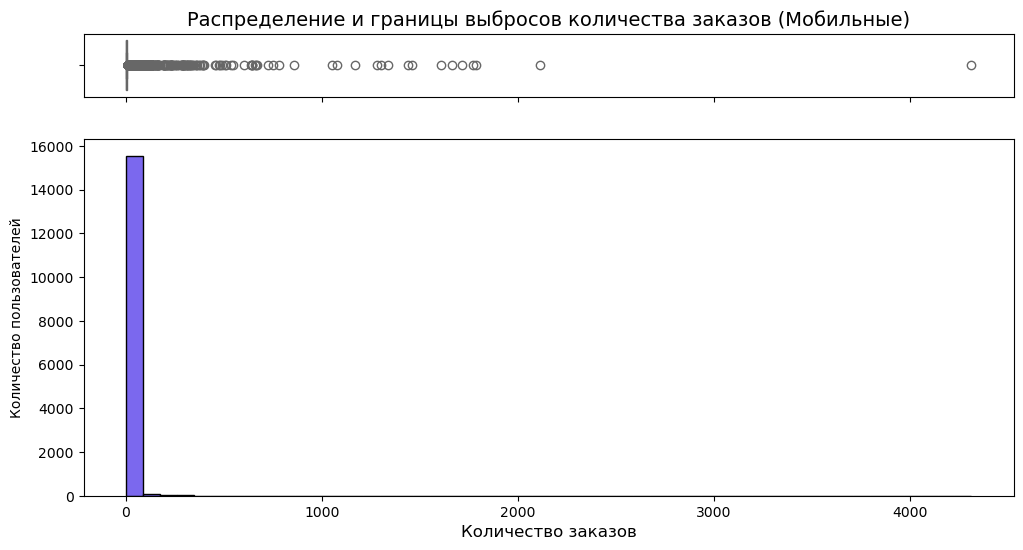

,mobile_user_orders
count,15731.00
mean,8.49
std,64.39
min,0.00
25%,1.00
50%,2.00
75%,4.00
max,4313.00


------------------------------------------------------------------------------------------------------------------------------------------------------


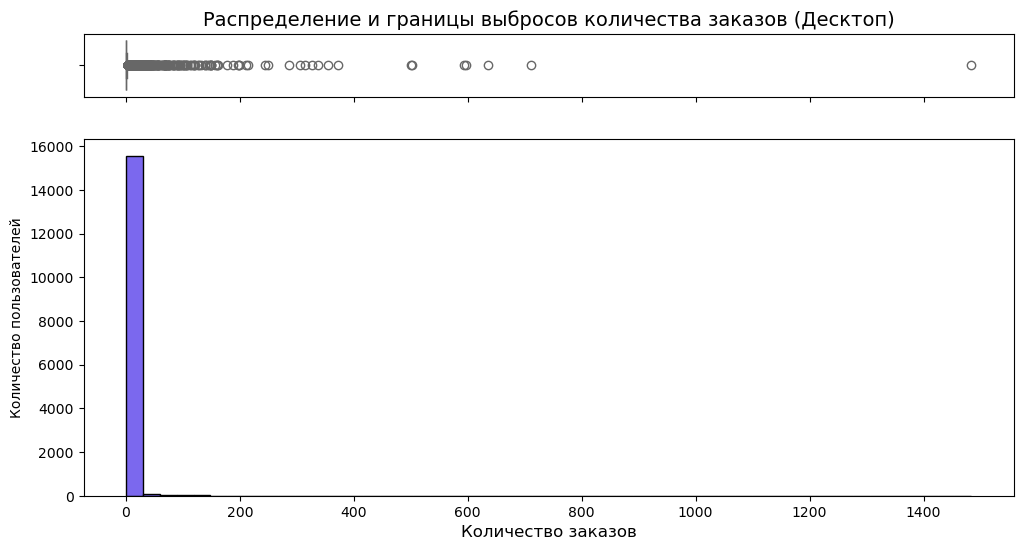

,desktop_user_orders
count,15731.00
mean,2.17
std,20.15
min,0.00
25%,0.00
50%,0.00
75%,1.00
max,1484.00


In [105]:
plot_hist_and_box(
    data_series=user_orders_autumn['mobile_user_orders'],
    title_name='Распределение и границы выбросов количества заказов (Мобильные)',
    xlabel_name='Количество заказов',
    ylabel_name='Количество пользователей'
)

print("-" * 150)

plot_hist_and_box(
    data_series=user_orders_autumn['desktop_user_orders'],
    title_name='Распределение и границы выбросов количества заказов (Десктоп)',
    xlabel_name='Количество заказов',
    ylabel_name='Количество пользователей'
)

<br>**Вывод по анализу результатов визуализации и описательных статистик**
<br>Изучив распределения и числовые метрики, можно сделать несколько важных выводов о поведении пользователей осенью:

1. **Сильная асимметрия данных.** Распределения количества заказов как на мобильных устройствах, так и на десктопе далеки от нормального. Они имеют экстремально длинные «хвосты» в правую сторону. В данных присутствуют аномально активные клиенты (оптовики или технические аккаунты): в мобильном приложении один пользователь совершил максимум 4313 заказов, а на сайте — 1484 заказа.
2. **Искажение средних значений.** Из-за этих единичных крупных выбросов стандартное среднее арифметическое сильно завышено (8.49 заказа на мобильных и 2.17 на десктопе). Оно не отражает поведение обычного, среднестатистического покупателя.
3. **Различия в медианной активности (главный инсайт).** Если мы посмотрим на медиану (показатель 50% в таблице), то увидим принципиальное различие:
   * Для мобильного приложения медиана равна **2.00**. Это значит, что типичный пользователь делает за осень 2 заказа через телефон.
   * Для десктопной версии сайта медиана равна **0.00**. Более того, показатели 25% и минимальное значение тоже равны нулю. Это говорит о том, что **более половины (50%) всех активных пользователей за всю осень не сделали с компьютера ни одного заказа**, полностью отдав предпочтение мобильному приложению.

Таким образом, выборки наглядно демонстрируют сильный перекос активности в сторону мобильного приложения. Однако для окончательного утверждения нам необходимо подтвердить это математически.

<br>

**Выбор статистического критерия**

Поскольку мы анализируем поведение одной и той же группы из 15 731 пользователя на двух разных устройствах, наши выборки являются зависимыми (связанными). Учитывая это, а также сильную асимметрию и наличие экстремальных выбросов, классический парный t-тест использовать нельзя. 

В качестве математического инструмента мы выбираем непараметрический **критерий Вилкоксона для связанных выборок** (`scipy.stats.wilcoxon`). Он устойчив к аномалиям, так как оценивает не абсолютные значения количества заказов, а ранги разностей внутри пар, что позволит получить объективный результат без искусственного удаления крупных клиентов.

<br>

#### <a id="p4_1_2"></a> Формулирование гипотез, проведение теста и подведение итогов

В этом подразделе мы переходим к финальной математической проверке. На основе выявленных особенностей данных мы сформулируем строгие статистические гипотезы для одностороннего теста Вилкоксона, запустим расчет критерия и посмотрим на полученный результат. На основе теста мы сделаем вывод о том, можно ли отвергнуть нулевую гипотезу или нет.

<br>

**Формулирование статистических гипотез**

Поскольку продуктовая команда предполагает, что пользователи в мобильном приложении активнее, мы будем проводить односторонний статистический тест. В коде библиотеки `scipy` для этого мы укажем параметр `alternative='greater'`, чтобы проверить сдвиг распределения в большую сторону. Сформулируем гипотезы:

* **Нулевая гипотеза ($H_0$):** Количество заказов на одного пользователя в мобильном приложении меньше или равно количеству заказов на стационарных устройствах.
* **Альтернативная гипотеза ($H_1$):** Количество заказов на одного пользователя в мобильном приложении больше, чем на стационарных устройствах.

<br>*Установим стандартный критический уровень значимости:*

In [106]:
alpha = 0.05

<br>*Проводим односторонний тест Вилкоксона для связанных выборок:*

In [107]:
statistic, p_value = wilcoxon(
    user_orders_autumn['mobile_user_orders'],
    user_orders_autumn['desktop_user_orders'],
    alternative='greater'
)

<br>*Сравниваем полученное `p-value` с уровнем значимости и выводим результаты теста:*

In [108]:
print(f"\nСтатистика критерия Вилкоксона: {statistic}")
print(f"Полученное значение p-value: {p_value}\n")

if p_value > alpha:
    print(f'p-value: {p_value:.7f} > {alpha}')
    print('Статистический вывод: Не получилось отвергнуть нулевую гипотезу.')
else:
    print(f'p-value: {p_value:.7f} < {alpha}')
    print('Статистический вывод: Отвергаем нулевую гипотезу.')
    


Статистика критерия Вилкоксона: 103582927.5
Полученное значение p-value: 0.0

p-value: 0.0000000 < 0.05
Статистический вывод: Отвергаем нулевую гипотезу.


<br>**Итоги проверки первой гипотезы:**

По результатам проведенного статистического **теста Вилкоксона** мы получили значение `p-value` близкое к `«0»`, которое оказалось существенно меньше установленного уровня значимости $\alpha = 0.05$. 

* **Статистический вывод:** Полученные данные дают нам полное основание **отвергнуть нулевую гипотезу ($H_0$)**. Разница в активности пользователей на разных устройствах огромна и не является случайной.
* **Вывод для бизнеса:** Математика полностью подтвердила то, что мы видели на графиках. Осенью пользователи в мобильном приложении покупают гораздо активнее, чем на сайте. Типичный клиент делает через приложение 2 заказа за сезон, в то время как с компьютера больше половины пользователей вообще ничего не заказывали (медиана равна 0).

Первое предположение продуктовой команды полностью подтвердилось: мобильное приложение — это главный канал продаж для наших клиентов в осенний период.

<br>

### <a id="p4_2"></a> Сравнение времени между заказами пользователей

В данном подразделе мы проверим второе предположение продуктовой команды: действительно ли интервал времени между заказами у пользователей мобильное устройство за осень больше, чем у тех, кто покупает через стационарный компьютер. 

Для этого мы сначала подготовим данные, рассчитаем временные интервалы между последовательными покупками, изучим их распределение, подберем верный статистический критерий, сформулируем гипотезы и проведем расчет.

<br>

#### <a id="p4_2_1"></a> Подготовка данных и исследование распределений времени между заказами

Перед тем как переходить к статистической проверке, необходимо исследовать структуру временных интервалов между покупками. Единицей наблюдения в данном анализе будет выступать отдельный интервал между двумя последовательными заказами клиента. 

Используя готовые данные о количестве дней с момента предыдущего заказа и типе устройства, мы сформируем две независимые выборки интервалов: для мобильных устройств и для стационарных компьютеров. На этом же этапе мы очистим данные от пустых значений, которые возникают при первой покупке пользователя, и визуализируем полученные распределения с помощью графиков.

<br>*Фильтруем осенние данные для **мобильных устройств** и удаляем пропуски:*

In [109]:
mobile_intervals = autumn_df[autumn_df['device_type_canonical'] == 'mobile']['days_since_prev'].dropna()

<br>*Фильтруем осенние данные для **стационарных компьютеров** и удаляем пропуски:*

In [110]:
desktop_intervals = autumn_df[autumn_df['device_type_canonical'] == 'desktop']['days_since_prev'].dropna()

<br>*С помощью фукции `plot_hist_and_box` строим графики распределения интервалов **для мобильных** устройств и **для стационарных** компьютеров:*

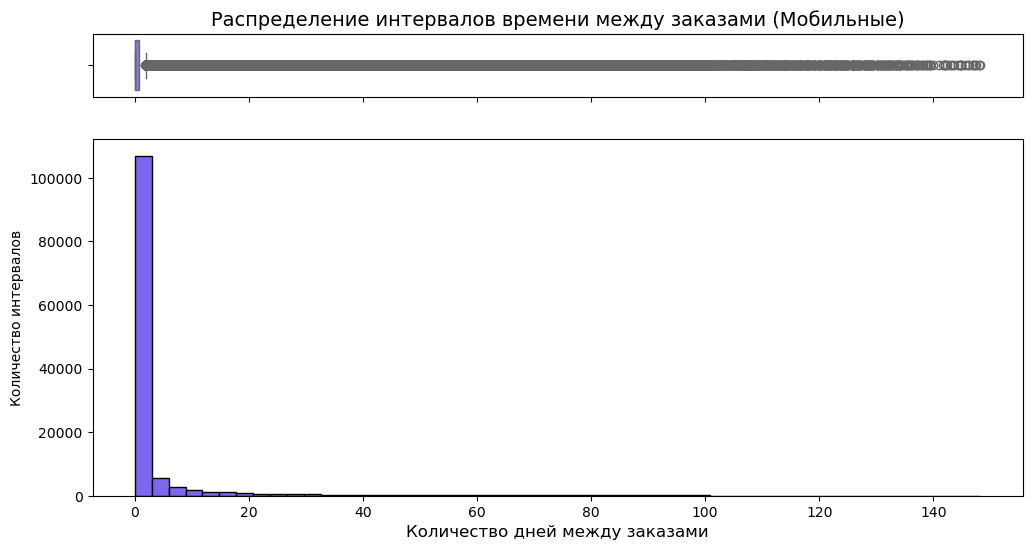

,days_since_prev
count,126644.00
mean,3.77
std,13.35
min,0.00
25%,0.00
50%,0.03
75%,0.81
max,148.23


------------------------------------------------------------------------------------------------------------------------------------------------------


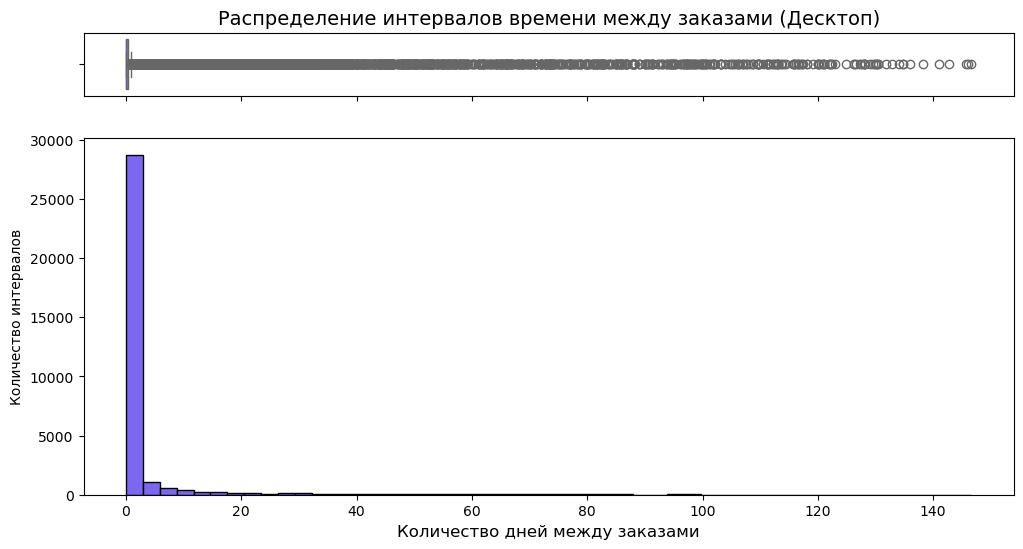

,days_since_prev
count,32826.00
mean,3.02
std,12.08
min,0.00
25%,0.00
50%,0.01
75%,0.37
max,146.63


In [111]:
plot_hist_and_box(
    data_series=mobile_intervals,
    title_name='Распределение интервалов времени между заказами (Мобильные)',
    xlabel_name='Количество дней между заказами',
    ylabel_name='Количество интервалов'
)

print("-" * 150)

plot_hist_and_box(
    data_series=desktop_intervals,
    title_name='Распределение интервалов времени между заказами (Десктоп)',
    xlabel_name='Количество дней между заказами',
    ylabel_name='Количество интервалов'
)

<br>**Анализ результатов визуализации времени между заказами**

Графики и таблицы метрик позволяют сделать важные выводы о структуре временных интервалов:
* **Экстремальная скошенность и характер данных:** Распределения в обеих группах имеют колоссальную асимметрию с огромными «хвостами» вправо (максимумы достигают 148 дней – для мобильных и 146 дней – для десктопа). При этом подавляющее большинство повторных покупок происходит практически мгновенно — в первые же сутки, а медианные значения и вовсе измеряются минутами (0.03 – дня для мобильных и 0.01 день – для десктопа). Это указывает на то, что клиенты часто оформляют несколько заказов подряд в рамках одной покупательской сессии.
* **Объемы выборок:** Количество зафиксированных интервалов в мобильном приложении (126 644) почти в 4 раза превышает показатель десктопа (32 826). Это полностью согласуется с нашими прошлыми выводами о том, что мобильные устройства генерируют основной поток транзакций.

<br>**Выбор статистического критерия**

Поскольку единицами наблюдения являются отдельные независимые события (интервалы), а сами данные распределены далеко не нормально и перегружены выбросами, для проверки гипотезы нам идеально подойдет непараметрический **критерий Манна-Уитни для независимых выборок** (`scipy.stats.mannwhitneyu`).

<br>

#### <a id="p4_2_2"></a> Формулирование гипотез, проведение теста и подведение итогов

В данном подразделе мы переходим к математической проверке второго предположения. Мы сформулируем строгие статистические гипотезы, выполним расчет критерия Манна-Уитни для независимых выборок и интерпретируем полученный результат с точки зрения статистической и практической значимости.

<br>

**Формулирование статистических гипотез**

Поскольку продуктовая команда предполагает, что интервалы времени между заказами на мобильных устройствах выше (длиннее), мы будем проводить односторонний тест. В коде библиотеки `scipy` мы укажем параметр `alternative='greater'`, чтобы проверить сдвиг распределения в сторону бóльших значений. Сформулируем гипотезы:

* **Нулевая гипотеза ($H_0$):** Время между заказами у пользователей мобильных устройств меньше или равно времени между заказами у пользователей стационарных компьютеров.
* **Альтернативная гипотеза ($H_1$):** Время между заказами у пользователей мобильных устройств больше, чем у пользователей стационарных компьютеров.

<br>*Задаём стандартный уровень значимости:*

In [112]:
alpha = 0.05

<br>*Проводим односторонний тест Манна-Уитни на то, что время у `mobile` **БОЛЬШЕ**, чем у `desktop`:*

In [113]:
stat_mw, p_value_mw = mannwhitneyu(mobile_intervals, desktop_intervals, alternative='greater')

<br>*Сравниваем полученное `p-value_mw` с уровнем значимости и выводим итоговый результат:*

In [114]:
if p_value_mw > alpha:
    print(f'p-value: {p_value_mw:.7f} > {alpha}')
    print('Статистический вывод: Не получилось отвергнуть нулевую гипотезу. Время между заказами Не имеет значимых различий.')
else:
    print(f'p-value: {p_value_mw:.7f} < {alpha}')
    print('Статистический вывод: Отвергаем нулевую гипотезу. Время между заказами у мобильных пользователей значимо выше.')


p-value: 0.0000000 < 0.05
Статистический вывод: Отвергаем нулевую гипотезу. Время между заказами у мобильных пользователей значимо выше.


<br>**Итоги проверки второй гипотезы:**

По результатам теста Манна-Уитни мы получили значение `p-value`, которое практически равно нулю, что значительно меньше нашего уровня значимости 0.05.

* **Статистический вывод:** Полученные данные дают нам полное основание **отвергнуть нулевую гипотезу ($H_0$)**. Разница во времени между заказами на разных устройствах является статистически значимой.
* **Вывод для бизнеса:** Математический тест подтвердил, что распределения интервалов времени между покупками значимо различаются. Если посмотреть на реальные метрики, то медианное время возврата на десктопе составляет 0.01 дня (около 15 минут), а на мобильных устройствах — 0.03 дня (около 40 минут). Это говорит о том, что хотя на обеих платформах повторные заказы скорее всего происходят в рамках одной быстрой покупательской сессии, на мобильных устройствах этот интервал между транзакциями оказывается выше. 

Второе предположение продуктовой команды о том, что время между заказами в мобильном приложении выше (интервалы длиннее), статистически подтвердилось: пользователи мобильных устройств действительно выдерживают чуть бóльшую паузу между повторными заказами, чем пользователи десктопов.

<br>

### <a id="p4_3"></a> Итоги статистического анализа и методологическое обоснование

В рамках четвертого шага мы провели комплексную проверку двух рабочих предположений продуктовой команды. С учетом методологических особенностей данных были получены следующие результаты:

1. **Количество заказов (Первая гипотеза):** Статистический тест Вилкоксона позволил нам уверенно **отвергнуть нулевую гипотезу**. Активность пользователей в мобильном приложении значимо выше. Это имеет огромную практическую ценность для бизнеса: типичный пользователь мобильного приложения делает за осень 2 заказа, в то время как на десктопе более половины клиентов не совершили ни одной покупки (медиана равна 0).
2. **Время между заказами (Вторая гипотеза):** Тест Манна-Уитни также показал, что мы **отвергаем нулевую гипотезу**. Временные интервалы между покупками на разных устройствах имеют статистически значимые различия. Пользователи мобильных устройств выдерживают чуть бóльшую паузу между повторными заказами (медиана 0.03 дня), чем пользователи десктопов (медиана 0.01 дня).

***

**Математическое обоснование выбора критериев**

При работе с данными мы столкнулись с несколькими важными факторами, которые определили выбор математических инструментов для проверки гипотез:

* **Зависимость данных в первом тесте:** Поскольку один и тот же пользователь может совершать покупки и с телефона, и с компьютера, обычное разделение покупателей на две группы нарушило бы условие независимости. Для решения этой проблемы мы объединили всю активность по каждому конкретному пользователю, перейдя к анализу связанных (парных) выборок. В качестве инструмента был выбран непараметрический **критерий Вилкоксона**, который идеально работает со связанными данными.
* **Независимость данных во втором тесте:** Здесь мы анализировали не пользователей, а отдельные интервалы времени между транзакциями. Каждый такой интервал уникален и привязан к конкретному заказу, что делает эти события полностью независимыми друг от друга. Поэтому здесь мы применили **критерий Манна-Уитни** для независимых выборок.
* **Влияние аномалий и выбросов:** Для каждого типа устройства распределения данных оказались экстремально скошенными вправо. В таких условиях классические параметрические тесты (t-критерии Стьюдента) использовать нельзя, так как крупные выбросы сильно искажают средние значения. Выбранные нами критерии Вилкоксона и Манна-Уитни работают с рангами (порядковыми номерами значений), благодаря чему они абсолютно устойчивы к аномалиям и позволили получить объективный результат.

<br>

## <a id="p5"></a> Общий вывод и бизнес-рекомендации

<br>**1. Информация о входных данных и предобработке**

В рамках проекта исследованы данные об активности пользователей сервиса «Яндекс Афиша» за период с июня по октябрь 2024 года. На этапе предобработки данные очищены от пропусков и неявных дубликатов. Проведена оптимизация типов данных, снизившая нагрузку на память на 50%. В ходе фильтрации аномалий удалено 3.06% записей (осталось 281 590 строк).

<br>**2. Основные результаты исследовательского анализа (EDA)**

* **Востребованность мероприятий и сезонность:** Интерес к спортивным, театральным и новогодним (ёлки) событиям осенью переживает резкий всплеск, в то время как посещаемость выставок и выбор типов устройств пользователями остаются абсолютно стабильными. 
* **Динамика среднего чека:** Активизация осенней аудитории в массовых категориях сопровождается заметным снижением средней стоимости одного билета. Это указывает на то, что приток клиентов обеспечивается за счет более доступных ценовых сегментов или активных маркетинговых акций. Так как данные охватывают один изолированный год, эти сезонные изменения пока рассматриваются как сильные рабочие гипотезы.
* **Пользовательская активность и цикличность:** Продажи демонстрируют выраженную недельную цикличность. Стабильный рост посещаемости начинается со среды и достигает пика в пятницу. В выходные дни фиксируется спад общего числа заказов, однако средний чек в субботу и воскресенье достигает недельного максимума (около 195–200 руб.), что говорит о преобладании срочных покупок билетов по полной цене непосредственно перед мероприятиями. Также обнаружены аномальные всплески активности по вторникам и в начале каждого месяца (в среднем до 3.72 заказа на человека при падении чека до 157 руб.), что указывает на проведение крупных плановых распродаж либо на активность автоматизированных ботов-перекупщиков.
* **Лидеры среди регионов и партнеров:** Сервис представлен в 81 регионе, но рынок имеет экстремальную концентрацию: всего 7 регионов забирают 59.83% заказов, а Каменевский регион является абсолютным монополистом. Из 36 билетных операторов ТОП-7 контролируют 82.67% всех заказов и 76.41% общей выручки. Абсолютным лидером по объему выручки выступает оператор «Билеты без проблем», а по разнообразию репертуара — «Лови билет!».

<br>**3. Комментарий к результатам проверки гипотез**

* **Первая гипотеза:** Статистический тест Вилкоксона для связанных выборок подтвердил, что активность пользователей в мобильном приложении значимо выше, чем на десктопе. Типичный клиент (медиана) делает за осень через приложение 2 заказа, в то время как на десктопной версии сайта более половины пользователей вообще не совершили ни одной покупки (медиана равна 0).
* **Вторая гипотеза:** Тест Манна-Уитни для независимых интервалов времени показал, что временные промежутки между покупками на разных устройствах имеют статистически значимые различия. На обеих платформах повторные заказы чаще всего совершаются практически мгновенно — в течение первых суток, возможно в рамках одной быстрой сессии. На мобильных устройствах этот интервал между заказами оказывается чуть выше (медиана 0.03 дня против 0.01 дня на стационарных компьютерах).

<br>**4. Бизнес-рекомендации для команды «Яндекс Афиши»**

1. **Быстрые продажи в приложении:** Так как мобильные пользователи покупают активнее всего, а повторные заказы делают в первые же часы, их нужно стимулировать сразу. Стоит настроить блок с рекомендациями похожих событий прямо на экране успешной оплаты, пока сессия клиента еще активна.
2. **Проверка активности по вторникам:** Резкие всплески заказов по вторникам с падением чека похожи на работу автоматических ботов или перекупщиков. Технической команде нужно проверить этот поток данных и при необходимости внедрить защиту (например, капчу), чтобы билеты доставались реальным клиентам.
3. **Снижение рисков и работа с лидерами:**
   Наш анализ показал, что бизнес слишком сильно зависит всего от одного Каменевского региона и одного оператора («Билеты без проблем»). Это опасная ситуация — если у них что-то сломается, платформа потеряет половину выручки. Чтобы подстраховаться и заработать больше, нужно развивать другие направления:
   * **Прокачка сильных регионов:** Стоит вложиться в рекламу в Североярской области и остальных регионах из топ-7. Они уже дают 60% заказов и могут приносить ещё больше, что поможет снизить зависимость от лидера.
   * **Ставка на эффективного партнёра:** Особое внимание стоит обратить на оператора «Мой билет». Имея небольшое количество мероприятий (всего 5.88% от общего числа), он генерирует 12.21% всех заказов и приносит 14.77% всей выручки. Это говорит о высоком спросе на его билеты. Нужно предложить ему более выгодные условия или расширить ассортимент его событий, чтобы увеличить общие продажи платформы и составить конкуренцию лидеру.
   * **Привлечение местных игроков:** В мелких регионах нужно активнее подключать небольших локальных операторов. Это добавит на сайт уникальные местные события и привлечёт новых покупателей, которых раньше не было.

<br>